In [2]:
import os
import sys
from pathlib import Path

os.chdir(r'C:\Users\HP\Documents\Economy\economia_c')
sys.path.insert(0, str(Path.cwd()))

print("CWD:", Path.cwd())
print("src OK:", (Path.cwd() / "src").exists())

CWD: C:\Users\HP\Documents\Economy\economia_c
src OK: True


In [6]:
import pandas as pd
from pathlib import Path
from src.prima_salarial import parsear_hoja_remuneraciones

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
RUTA_REMUN = RAIZ / "data" / "raw" / "provinciales_serie_remuneraciones_mensual_4dig_7.xlsx"

df = parsear_hoja_remuneraciones(RUTA_REMUN, "La Rioja")
print("Columnas:", df.columns.tolist())
print("Shape:", df.shape)
print("\nPrimeras filas:")
print(df.head(3).to_string())

Columnas: ['ciiu', 'rama', 'anio', 'mes', 'salario']
Shape: (34223, 5)

Primeras filas:
   ciiu                                                                      rama  anio  mes     salario
0   111                             Cultivo de cereales, oleaginosas y forrajeras  1995    1  496.379700
1   113                  Cultivo de frutas  -excepto vid para vinificar- y nueces  1995    1  290.587585
2   114  Cultivos industriales, de especias y de plantas aromáticas y medicinales  1995    1  317.466003


In [7]:
import pandas as pd
from pathlib import Path
from src.prima_salarial import parsear_hoja_remuneraciones
from src.empresas_ec import CIIU_EC

# Rutas
RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
RUTA_REMUN = RAIZ / "data" / "raw" / "provinciales_serie_remuneraciones_mensual_4dig_7.xlsx"
RUTA_SAL_PROV = RAIZ / "data" / "raw" / "SerieWeb_SALARIO_PRIVADO_FORMAL_provincias.xlsx"

# ============================================================
# 1. Salario EC por CIIU — último mes disponible de 2025
# ============================================================
df = parsear_hoja_remuneraciones(RUTA_REMUN, "La Rioja")
print("Columnas:", df.columns.tolist(), "\n")

# Filtrar por código CIIU EC y año 2025
ec25 = df[(df['ciiu'].isin(CIIU_EC.keys())) & (df['anio']==2025)]

# Último mes con dato
meses_con_dato = sorted(ec25.dropna(subset=['salario'])['mes'].unique())
ultimo_mes = max(meses_con_dato)
print(f"Último mes de 2025 con dato: {ultimo_mes}")
print(f"Meses disponibles: {meses_con_dato}\n")

ec_ult = ec25[ec25['mes'] == ultimo_mes]

print(f"{'CIIU':<6} {'Descripción':<55} {'Salario':>15}")
print("-" * 78)
for ciiu in sorted(CIIU_EC.keys()):
    sub = ec_ult[ec_ult['ciiu'] == ciiu]
    desc = CIIU_EC[ciiu][:53]
    if sub.empty or sub['salario'].isna().all():
        print(f"{ciiu:<6} {desc:<55} {'s.d.':>15}")
    else:
        val = sub['salario'].iloc[0]
        print(f"{ciiu:<6} {desc:<55} ${val:>13,.0f}")

# ============================================================
# 2. Salario provincial — leer Excel directo
# ============================================================
raw = pd.read_excel(RUTA_SAL_PROV,
                     sheet_name="Remuneraciones_promedio_privado",
                     header=None, engine="openpyxl")

# Buscar fila de La Rioja
fila_lr = None
for i in range(len(raw)):
    if str(raw.iloc[i, 0]).strip() == "La Rioja":
        fila_lr = i
        break

if fila_lr is None:
    print("\n⚠️ No encontré 'La Rioja' en el Excel provincial")
else:
    headers = raw.iloc[0].tolist()
    valores = raw.iloc[fila_lr].tolist()

    print("\nÚltimos 6 períodos provinciales:")
    print(f"{'Período':<25} {'Valor':>15}")
    print("-" * 42)
    count = 0
    for j in range(len(headers) - 1, 0, -1):
        try:
            v = float(valores[j])
            print(f"{str(headers[j]):<25} ${v:>13,.0f}")
            count += 1
            if count >= 6:
                break
        except (ValueError, TypeError):
            continue

Columnas: ['ciiu', 'rama', 'anio', 'mes', 'salario'] 

Último mes de 2025 con dato: 12
Meses disponibles: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

CIIU   Descripción                                                     Salario
------------------------------------------------------------------------------
7210   Consultores en equipo de informática                               s.d.
7220   Consultores en informática y suministros de programas   $    2,786,240
7250   Mantenimiento y reparación de maq. informática                     s.d.
7290   Actividades de informática n.c.p.                       $    4,220,278
7300   Investigación y desarrollo                                         s.d.
7421   Servicios de arquitectura e ingeniería                  $    1,566,575
7430   Servicios de publicidad                                            s.d.
7499   Servicios empresar

In [8]:
import pandas as pd
from pathlib import Path
from src.prima_salarial import parsear_hoja_remuneraciones
from src.empresas_ec import CIIU_EC

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
RUTA_REMUN = RAIZ / "data" / "raw" / "provinciales_serie_remuneraciones_mensual_4dig_7.xlsx"
RUTA_SAL_PROV = RAIZ / "data" / "raw" / "SerieWeb_SALARIO_PRIVADO_FORMAL_provincias.xlsx"

# ============================================================
# 1. Promedio 2025 por CIIU EC
# ============================================================
df = parsear_hoja_remuneraciones(RUTA_REMUN, "La Rioja")
ec25 = df[(df['ciiu'].isin(CIIU_EC.keys())) & (df['anio']==2025)]

# Cuántos meses tiene cada CIIU
print("Meses con dato por CIIU (2025):")
for ciiu in sorted(CIIU_EC.keys()):
    n = ec25[(ec25['ciiu']==ciiu) & (ec25['salario'].notna())].shape[0]
    print(f"  {ciiu}: {n} meses")

print()

# Promedio 2025 por CIIU
prom_ec = (ec25.groupby('ciiu')['salario']
           .agg(['mean', 'count'])
           .round(0))

print(f"{'CIIU':<6} {'Descripción':<50} {'Promedio 2025':>18} {'Meses':>6}")
print("-" * 82)
for ciiu in sorted(CIIU_EC.keys()):
    desc = CIIU_EC[ciiu][:48]
    if ciiu in prom_ec.index and pd.notna(prom_ec.loc[ciiu, 'mean']):
        v = prom_ec.loc[ciiu, 'mean']
        n = int(prom_ec.loc[ciiu, 'count'])
        print(f"{ciiu:<6} {desc:<50} ${v:>16,.0f} {n:>6}")
    else:
        print(f"{ciiu:<6} {desc:<50} {'s.d.':>18} {0:>6}")

# ============================================================
# 2. Provincial promedio 2025
# ============================================================
prov = pd.read_excel(RUTA_SAL_PROV,
                     sheet_name="Remuneraciones_promedio_privado",
                     header=None, engine="openpyxl")

for i in range(len(prov)):
    if str(prov.iloc[i, 0]).strip() == "La Rioja":
        headers = prov.iloc[0].tolist()
        valores = prov.iloc[i].tolist()
        suma, n = 0.0, 0
        print("\nMeses 2025 provinciales:")
        for j, h in enumerate(headers):
            h_str = str(h).lower()
            # Busca meses 2025 (formato YYYY-MM-DD o "mmm-25")
            es_2025 = '2025' in str(h) or 'ene-25' in h_str or 'feb-25' in h_str or \
                      'mar-25' in h_str or 'abr-25' in h_str or 'may-25' in h_str or \
                      'jun-25' in h_str or 'jul-25' in h_str or 'ago-25' in h_str or \
                      'sep-25' in h_str or 'oct-25' in h_str or 'nov-25' in h_str or \
                      'dic-25' in h_str
            if es_2025:
                try:
                    v = float(valores[j])
                    suma += v
                    n += 1
                    print(f"  {h}: ${v:>13,.0f}")
                except (ValueError, TypeError):
                    pass
        if n > 0:
            print(f"\n➡️ Provincial promedio 2025: ${suma/n:,.0f}  (de {n} meses)")
        break

Meses con dato por CIIU (2025):
  7210: 0 meses
  7220: 12 meses
  7250: 9 meses
  7290: 12 meses
  7300: 0 meses
  7421: 12 meses
  7430: 0 meses
  7499: 12 meses

CIIU   Descripción                                             Promedio 2025  Meses
----------------------------------------------------------------------------------
7210   Consultores en equipo de informática                             s.d.      0
7220   Consultores en informática y suministros de prog   $       1,726,147     12
7250   Mantenimiento y reparación de maq. informática     $         169,957      9
7290   Actividades de informática n.c.p.                  $       3,108,543     12
7300   Investigación y desarrollo                                       s.d.      0
7421   Servicios de arquitectura e ingeniería             $       1,016,111     12
7430   Servicios de publicidad                                          s.d.      0
7499   Servicios empresariales n.c.p.                     $         978,907     12



In [9]:
# ============================================================
# VERIFICACIÓN: Empleo núcleo software vs EC completo (8 CIIU)
# ============================================================
import os, sys, re
from pathlib import Path
import pandas as pd
import numpy as np

# --- 1. Setup de entorno ---
RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

print(f'📂 Raíz: {RAIZ}')
print(f'🐍 Python: {sys.version.split()[0]}')

# --- 2. Verificar archivo procesado ---
ruta_proc = RAIZ / 'data' / 'processed' / 'empleo_ec_rioja.xlsx'
print(f'\n📄 Archivo: {ruta_proc}')
print(f'   Existe: {ruta_proc.exists()}')
if not ruta_proc.exists():
    raise FileNotFoundError(f'No existe {ruta_proc}')
print(f'   Modificado: {pd.Timestamp(ruta_proc.stat().st_mtime, unit="s")}')

xl = pd.ExcelFile(ruta_proc)
print(f'\n📑 Hojas disponibles: {xl.sheet_names}')

# --- 3. Leer la hoja clave (con fallback por nombre) ---
hoja_objetivo = None
for nombre in ['Empleo_EC_trimestral', 'Empleo_EC', 'empleo_ec_trimestral', 'Empleo_EC_trim']:
    if nombre in xl.sheet_names:
        hoja_objetivo = nombre
        break
if hoja_objetivo is None:
    print('⚠️ No se encontró hoja esperada. Usando la primera hoja.')
    hoja_objetivo = xl.sheet_names[0]

print(f'\n🔍 Leyendo hoja: {hoja_objetivo}')
df = pd.read_excel(ruta_proc, sheet_name=hoja_objetivo)
print(f'   Shape: {df.shape}')
print(f'   Columnas: {df.columns.tolist()}')
print('\nPrimeras 8 filas:')
display(df.head(8))
print('\nTipos:')
print(df.dtypes)

# --- 4. Normalizar nombres de columnas ---
df.columns = [str(c).strip().lower() for c in df.columns]

# Detección flexible de columnas
def _buscar(opciones, cols):
    for o in opciones:
        if o in cols:
            return o
    return None

col_anio   = _buscar(['anio','año','year'], df.columns)
col_trim   = _buscar(['trimestre','trim','periodo','per'], df.columns)
col_ciiu   = _buscar(['ciiu','codigo_ciiu','cod_ciiu','codigo'], df.columns)
col_empleo = _buscar(['empleo','puestos','empleo_ec','valor'], df.columns)

print(f'\n🔧 Columnas detectadas:')
print(f'   año    → {col_anio}')
print(f'   trim   → {col_trim}')
print(f'   ciiu   → {col_ciiu}')
print(f'   empleo → {col_empleo}')

if not all([col_anio, col_ciiu, col_empleo]):
    print('\n⚠️ Faltan columnas clave. Revisá manualmente los nombres.')
    print(df.head())
    raise SystemExit('Detener: revisar columnas')

# --- 5. Limpiar tipos ---
# Año: extraer 4 dígitos si viene como string tipo "1° Trim 2019"
if df[col_anio].dtype == object:
    df[col_anio] = df[col_anio].astype(str).str.extract(r'((?:19|20)\d{2})')[0]
df[col_anio] = pd.to_numeric(df[col_anio], errors='coerce')

# Trimestre: extraer número si viene como texto
if col_trim and df[col_trim].dtype == object:
    df['_trim_num'] = df[col_trim].astype(str).str.extract(r'(\d)')[0]
    df['_trim_num'] = pd.to_numeric(df['_trim_num'], errors='coerce')
    col_trim_use = '_trim_num'
else:
    col_trim_use = col_trim

# CIIU: extraer 4 dígitos
df[col_ciiu] = df[col_ciiu].astype(str).str.extract(r'(\d{4})')[0]
df[col_ciiu] = pd.to_numeric(df[col_ciiu], errors='coerce')

# Empleo: numérico
df[col_empleo] = pd.to_numeric(df[col_empleo], errors='coerce')

df = df.dropna(subset=[col_anio, col_ciiu, col_empleo])
df[col_anio] = df[col_anio].astype(int)
df[col_ciiu] = df[col_ciiu].astype(int)

print(f'\n✅ Filas válidas tras limpieza: {len(df)}')
print(f'   Años: {sorted(df[col_anio].unique().tolist())}')
print(f'   CIIU únicos: {sorted(df[col_ciiu].unique().tolist())}')

# --- 6. Cálculo núcleo SW vs EC completo ---
CIIU_NUCLEO_SW   = {7220, 7250, 7290}
CIIU_EC_COMPLETO = {7210, 7220, 7250, 7290, 7300, 7421, 7430, 7499}

df_nuc  = df[df[col_ciiu].isin(CIIU_NUCLEO_SW)].copy()
df_comp = df[df[col_ciiu].isin(CIIU_EC_COMPLETO)].copy()

# Agrupar por año (y trimestre si existe) y promediar anual
if col_trim_use and col_trim_use in df.columns:
    nuc_anual  = (df_nuc.groupby([col_anio, col_trim_use])[col_empleo].sum()
                        .groupby(col_anio).mean().round(0))
    comp_anual = (df_comp.groupby([col_anio, col_trim_use])[col_empleo].sum()
                        .groupby(col_anio).mean().round(0))
    print('\n📊 Promedios anuales calculados desde trimestres')
else:
    nuc_anual  = df_nuc.groupby(col_anio)[col_empleo].mean().round(0)
    comp_anual = df_comp.groupby(col_anio)[col_empleo].mean().round(0)
    print('\n📊 Promedios anuales calculados desde registros disponibles')

# --- 7. Comparar con dashboard ---
dashboard_8ciiu = {2019:356, 2020:298, 2021:336, 2022:445,
                   2023:513, 2024:506, 2025:521}

resultado = pd.DataFrame({
    'Núcleo SW (7220+7250+7290)': nuc_anual,
    'EC completo 8 CIIU':         comp_anual,
    'Dashboard 8 CIIU (esperado)': pd.Series(dashboard_8ciiu),
})
resultado['Diferencia'] = resultado['EC completo 8 CIIU'] - resultado['Dashboard 8 CIIU (esperado)']
resultado = resultado.sort_index()

print('\n' + '='*70)
print('📋 RESULTADO VERIFICACIÓN')
print('='*70)
display(resultado)

# --- 8. Diagnóstico ---
print('\n🔎 Diagnóstico:')
dif_max = resultado['Diferencia'].abs().max()
if pd.isna(dif_max):
    print('   ⚠️ No hay años en común para comparar.')
elif dif_max <= 1:
    print('   ✅ COINCIDE con el dashboard. Los archivos procesados son correctos.')
elif dif_max <= 10:
    print(f'   🟡 Diferencia menor (máx {dif_max:.0f}). Probablemente redondeo o años parciales.')
else:
    print(f'   🔴 Diferencia significativa (máx {dif_max:.0f}). Revisar fuente o regenerar.')
    print('   → El archivo procesado puede estar desactualizado o con otra definición.')

# --- 9. Guardar resultado ---
salida = RAIZ / 'data' / 'processed' / 'verificacion_empleo_nucleo.csv'
resultado.to_csv(salida, encoding='utf-8-sig')
print(f'\n💾 Guardado: {salida}')

# --- 10. Bonus: verificacion archivos raw ---
print('\n' + '='*70)
print('📁 ESTADO DE ARCHIVOS RAW')
print('='*70)
raws = [
    'provinciales_serie_empleo_trimestral_4dig_7.xlsx',
    'provinciales_serie_remuneraciones_mensual_4dig_7.xlsx',
    'SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx',
    'SerieWeb_SALARIO_PRIVADO_FORMAL_provincias.xlsx',
    'provinciales_serie_empresas3_2.xlsx',
]
for r in raws:
    p = RAIZ / 'data' / 'raw' / r
    if p.exists():
        fecha = pd.Timestamp(p.stat().st_mtime, unit='s')
        print(f'   ✅ {r:60s} → {fecha}')
    else:
        print(f'   ❌ {r:60s} → NO EXISTE')
        

📂 Raíz: C:\Users\HP\Documents\Economy\economia_c
🐍 Python: 3.14.5

📄 Archivo: C:\Users\HP\Documents\Economy\economia_c\data\processed\empleo_ec_rioja.xlsx
   Existe: True
   Modificado: 2026-09-20 01:35:39.841192961

📑 Hojas disponibles: ['Sheet1']
⚠️ No se encontró hoja esperada. Usando la primera hoja.

🔍 Leyendo hoja: Sheet1
   Shape: (28, 2)
   Columnas: ['anio', 'empleo_ec_prom']

Primeras 8 filas:


,anio,empleo_ec_prom
0,1997,2.25
1,1998,3.50
2,1999,22.75
3,2000,5.50
4,2001,9.50
5,2003,9.75
6,2004,11.00
7,2005,11.25



Tipos:
anio                int64
empleo_ec_prom    float64
dtype: object

🔧 Columnas detectadas:
   año    → anio
   trim   → None
   ciiu   → None
   empleo → None

⚠️ Faltan columnas clave. Revisá manualmente los nombres.
   anio  empleo_ec_prom
0  1997            2.25
1  1998            3.50
2  1999           22.75
3  2000            5.50
4  2001            9.50


SystemExit: Detener: revisar columnas

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\IPython\core\interactiveshell.py:3831: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)


In [10]:
# ============================================================
# VERIFICACIÓN v2: Empleo EC desde el RAW trimestral (4 dígitos)
# ============================================================
import os, sys, re
from pathlib import Path
import pandas as pd
import numpy as np

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

ruta_raw = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'
print(f'📄 RAW: {ruta_raw}')
print(f'   Existe: {ruta_raw.exists()}')
if not ruta_raw.exists():
    raise FileNotFoundError(ruta_raw)
print(f'   Modificado: {pd.Timestamp(ruta_raw.stat().st_mtime, unit="s")}')

xl = pd.ExcelFile(ruta_raw)
print(f'\n📑 Hojas: {xl.sheet_names}')

# --- Inspección de cada hoja ---
for h in xl.sheet_names:
    df_h = pd.read_excel(ruta_raw, sheet_name=h, nrows=5)
    print(f'\n--- Hoja: "{h}" ---')
    print(f'   Shape (solo 5 filas leídas): {df_h.shape}')
    print(f'   Columnas: {df_h.columns.tolist()}')
    print(df_h.head(3).to_string())

📄 RAW: C:\Users\HP\Documents\Economy\economia_c\data\raw\provinciales_serie_empleo_trimestral_4dig_7.xlsx
   Existe: True
   Modificado: 2026-08-05 02:25:07.148713112

📑 Hojas: ['Caratula', 'Indice', 'GBA', 'CABA', 'Resto de Buenos Aires', 'Catamarca', 'Córdoba', 'Corrientes', 'Chaco', 'Chubut', 'Entre Ríos', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquén', 'Río Negro', 'Salta', 'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fe', 'Santiago del Estero', 'Tucumán', 'Tierra del Fuego', 'Metodología']

--- Hoja: "Caratula" ---
   Shape (solo 5 filas leídas): (0, 0)
   Columnas: []
Empty DataFrame
Columns: []
Index: []

--- Hoja: "Indice" ---
   Shape (solo 5 filas leídas): (3, 2)
   Columnas: ['Unnamed: 0', 'Unnamed: 1']
   Unnamed: 0                                                                                                       Unnamed: 1
0         NaN                                                   Índice Boletín Trimestral de Empleo por Provincias a 4 

In [11]:
# ============================================================
# VERIFICACIÓN v3: Estructura interna de la hoja "La Rioja"
# ============================================================
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta_raw = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

# Leer SIN header para ver todo crudo
df = pd.read_excel(ruta_raw, sheet_name='La Rioja', header=None)
print(f'Shape completo: {df.shape}')
print(f'\nPrimeras 15 filas (todas las columnas, truncadas):')
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 250)
print(df.iloc[:15, :8].to_string())

print(f'\nÚltimas 5 filas (primeras 8 columnas):')
print(df.iloc[-5:, :8].to_string())

# Ver los valores de la primera columna (donde suele estar el CIIU)
print(f'\nPrimera columna, primeros 30 valores únicos (no nulos):')
col0 = df.iloc[:, 0].dropna().astype(str).unique()
for v in col0[:30]:
    print(f'   {repr(v)}')

Shape completo: (311, 122)

Primeras 15 filas (todas las columnas, truncadas):
                                                                                                                                               0                                                                           1             2             3             4             5             6             7
0                                                                                                                                            NaN                                                                         NaN           NaN           NaN           NaN           NaN           NaN           NaN
1                                                                                                                                       LA RIOJA                                                                         NaN           NaN           NaN           NaN           NaN           NaN           NaN
2   Em

In [12]:
# ============================================================
# VERIFICACIÓN v4: Empleo EC + núcleo SW desde "La Rioja"
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta_raw = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

# --- 1. Leer con header en fila 6 (0-indexed) ---
df = pd.read_excel(ruta_raw, sheet_name='La Rioja', header=6)
print(f'Shape crudo: {df.shape}')
print(f'Columnas (primeras 5): {df.columns[:5].tolist()}')
print(f'Columnas (últimas 3): {df.columns[-3:].tolist()}')

# --- 2. Limpiar filas ---
# Renombrar primeras dos columnas
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})

# Quedarnos con filas cuyo ciiu_raw sea un código de 4 dígitos
df['ciiu_raw_str'] = df['ciiu_raw'].astype(str).str.strip()
mask_4dig = df['ciiu_raw_str'].str.fullmatch(r'\d{4}')
df = df[mask_4dig].copy()
df['ciiu'] = df['ciiu_raw_str'].astype(int)

print(f'\nFilas con CIIU de 4 dígitos: {len(df)}')
print(f'CIIU únicos (primeros 20): {sorted(df["ciiu"].unique())[:20]}')

# --- 3. Detectar columnas de trimestres (2 a N) ---
cols_trim = [c for c in df.columns if isinstance(c, str) and 'Trim' in c]
print(f'\nColumnas de trimestres detectadas: {len(cols_trim)}')
print(f'   Primera: {cols_trim[0]}')
print(f'   Última:  {cols_trim[-1]}')

# --- 4. Extraer año de cada columna de trimestre ---
def anio_de_col(col):
    m = re.search(r'(19|20)\d{2}', str(col))
    return int(m.group()) if m else None

mapa_col_anio = {c: anio_de_col(c) for c in cols_trim}
anios_unicos = sorted(set(v for v in mapa_col_anio.values() if v is not None))
print(f'\nAños detectados: {anios_unicos[0]} ... {anios_unicos[-1]} (total {len(anios_unicos)})')

# --- 5. Convertir valores a numérico (s.d. → NaN) ---
sub = df[['ciiu'] + cols_trim].copy()
for c in cols_trim:
    sub[c] = pd.to_numeric(sub[c], errors='coerce')

# --- 6. Pasar a formato largo (long) ---
long = sub.melt(id_vars='ciiu', value_vars=cols_trim,
                var_name='trimestre', value_name='empleo')
long['anio'] = long['trimestre'].map(mapa_col_anio)
long = long.dropna(subset=['anio', 'empleo'])

# --- 7. Definir conjuntos ---
CIIU_NUCLEO_SW   = {7220, 7250, 7290}
CIIU_EC_COMPLETO = {7210, 7220, 7250, 7290, 7300, 7421, 7430, 7499}

# CIIU presentes en cada definición
sw_presentes = sorted(CIIU_NUCLEO_SW & set(long['ciiu'].unique()))
ec_presentes = sorted(CIIU_EC_COMPLETO & set(long['ciiu'].unique()))
print(f'\nCIIU núcleo SW presentes en el archivo: {sw_presentes}')
print(f'CIIU EC completos presentes:            {ec_presentes}')
print(f'Faltantes núcleo SW: {sorted(CIIU_NUCLEO_SW - set(sw_presentes))}')
print(f'Faltantes EC completo: {sorted(CIIU_EC_COMPLETO - set(ec_presentes))}')

# --- 8. Sumar por año: núcleo SW y EC completo ---
long_sw = long[long['ciiu'].isin(CIIU_NUCLEO_SW)]
long_ec = long[long['ciiu'].isin(CIIU_EC_COMPLETO)]

# Promedio anual = promedio de los trimestres del año (después de sumar los CIIU del grupo)
sw_anual = (long_sw.groupby(['anio', 'trimestre'])['empleo'].sum()
                   .groupby('anio').mean().round(0))
ec_anual = (long_ec.groupby(['anio', 'trimestre'])['empleo'].sum()
                   .groupby('anio').mean().round(0))

# --- 9. Tabla comparativa ---
dashboard_8ciiu = {2019:356, 2020:298, 2021:336, 2022:445,
                   2023:513, 2024:506, 2025:521}

resultado = pd.DataFrame({
    'Núcleo SW (7220+7250+7290)': sw_anual,
    'EC completo 8 CIIU':         ec_anual,
    'Dashboard 8 CIIU (esperado)': pd.Series(dashboard_8ciiu),
})
resultado['Diferencia'] = resultado['EC completo 8 CIIU'] - resultado['Dashboard 8 CIIU (esperado)']
resultado = resultado.loc[sorted(resultado.index)]

print('\n' + '='*72)
print('📋 RESULTADO: Empleo EC — Dashboard vs RAW')
print('='*72)
display(resultado)

# --- 10. Diagnóstico ---
dif = resultado['Diferencia'].dropna()
if len(dif) == 0:
    print('⚠️ No hay años en común para comparar.')
else:
    dif_max = dif.abs().max()
    if dif_max <= 1:
        print('✅ COINCIDE exactamente con el dashboard.')
    elif dif_max <= 10:
        print(f'🟡 Diferencia menor (máx {dif_max:.0f}). Probable redondeo o revisión.')
    else:
        print(f'🔴 Diferencia significativa (máx {dif_max:.0f}). Revisar definición.')

# --- 11. Exportar ---
salida = RAIZ / 'data' / 'processed' / 'empleo_ec_nucleo_sw.csv'
out = resultado.copy()
out.index.name = 'anio'
out.to_csv(salida, encoding='utf-8-sig')
print(f'\n💾 Guardado: {salida}')

# --- 12. Serie histórica larga (para gráficos) ---
serie_larga = pd.DataFrame({
    'nucleo_sw': sw_anual,
    'ec_completo': ec_anual,
}).dropna(how='all')
serie_larga.index.name = 'anio'
serie_larga.to_csv(RAIZ / 'data' / 'processed' / 'empleo_ec_serie_larga.csv',
                   encoding='utf-8-sig')
print(f'💾 Serie larga: data/processed/empleo_ec_serie_larga.csv')
print(f'   Años: {serie_larga.index.min()} → {serie_larga.index.max()}')

Shape crudo: (304, 122)
Columnas (primeras 5): ['Ramas', 'Descripción', '1° Trim 1996', '2° Trim 1996', '3° Trim 1996']
Columnas (últimas 3): ['2° Trim 2025', '3° Trim 2025', '4° Trim 2025']

Filas con CIIU de 4 dígitos: 284
CIIU únicos (primeros 20): [np.int64(1110), np.int64(1120), np.int64(1310), np.int64(1320), np.int64(1411), np.int64(1412), np.int64(1413), np.int64(1414), np.int64(1421), np.int64(1422), np.int64(1429), np.int64(1511), np.int64(1512), np.int64(1513), np.int64(1514), np.int64(1520), np.int64(1531), np.int64(1532), np.int64(1533), np.int64(1541)]

Columnas de trimestres detectadas: 120
   Primera: 1° Trim 1996
   Última:  4° Trim 2025

Años detectados: 1996 ... 2025 (total 30)

CIIU núcleo SW presentes en el archivo: [7220, 7250, 7290]
CIIU EC completos presentes:            [7220, 7250, 7290, 7300, 7421, 7430, 7499]
Faltantes núcleo SW: []
Faltantes EC completo: [7210]

📋 RESULTADO: Empleo EC — Dashboard vs RAW


C:\Users\HP\AppData\Local\Temp\ipykernel_10300\1102529654.py:23: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_raw_str'] = df['ciiu_raw'].astype(str).str.strip()


,Núcleo SW (7220+7250+7290),EC completo 8 CIIU,Dashboard 8 CIIU (esperado),Diferencia
1996,NaN,148.0,NaN,NaN
1997,2.0,210.0,NaN,NaN
1998,4.0,168.0,NaN,NaN
1999,23.0,194.0,NaN,NaN
2000,6.0,194.0,NaN,NaN
2001,10.0,194.0,NaN,NaN
2002,NaN,103.0,NaN,NaN
2003,10.0,130.0,NaN,NaN
2004,11.0,173.0,NaN,NaN
2005,11.0,205.0,NaN,NaN


✅ COINCIDE exactamente con el dashboard.

💾 Guardado: C:\Users\HP\Documents\Economy\economia_c\data\processed\empleo_ec_nucleo_sw.csv
💾 Serie larga: data/processed/empleo_ec_serie_larga.csv
   Años: 1996 → 2025


In [13]:
# ============================================================
# SerieWeb Empleo Privado Formal — inspección completa
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx'

print(f'📄 {ruta.name}')
print(f'   Modificado: {pd.Timestamp(ruta.stat().st_mtime, unit="s")}')

xl = pd.ExcelFile(ruta)
print(f'\n📑 Hojas: {xl.sheet_names}')

# Leer cada hoja cruda para ver estructura
for h in xl.sheet_names[:5]:
    df = pd.read_excel(ruta, sheet_name=h, header=None, nrows=12)
    print(f'\n--- Hoja: "{h}" (shape parcial: {df.shape}) ---')
    print(df.iloc[:12, :10].to_string())

📄 SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx
   Modificado: 2026-09-16 14:03:01.475758791

📑 Hojas: ['serie_original', 'serie_desestacionalizada', 'variaciones %']

--- Hoja: "serie_original" (shape parcial: (12, 211)) ---
                                   0                    1                    2                    3                    4                    5                    6                    7                    8                    9
0   -en miles de puestos de trabajo-  2009-01-01 00:00:00  2009-02-01 00:00:00  2009-03-01 00:00:00  2009-04-01 00:00:00  2009-05-01 00:00:00  2009-06-01 00:00:00  2009-07-01 00:00:00  2009-08-01 00:00:00  2009-09-01 00:00:00
1                             Bs. As              1787.64             1769.223             1745.913             1729.917             1723.218             1724.903             1722.949             1720.649             1727.501
2                               CABA             1469.941             1467.029             1466

In [16]:
raw = pd.read_excel(ruta, sheet_name='serie_original', header=0)
for c in raw.columns[1:]:
    if not isinstance(c, pd.Timestamp) and not hasattr(c, 'year'):
        print(f'  {repr(c)}   →  tipo: {type(c).__name__}')

  'feb-15'   →  tipo: str
  'mar-15'   →  tipo: str
  'abr-15'   →  tipo: str
  'may-15'   →  tipo: str
  'jun-15'   →  tipo: str
  'jul-15'   →  tipo: str
  'ago-15'   →  tipo: str
  'sep-15'   →  tipo: str
  'oct-15'   →  tipo: str
  'nov-15'   →  tipo: str
  'dic-15'   →  tipo: str
  'ene-16'   →  tipo: str
  'feb-16'   →  tipo: str
  'mar-16'   →  tipo: str
  'abr-16'   →  tipo: str
  'may-16'   →  tipo: str
  'jun-16'   →  tipo: str
  'jul-16'   →  tipo: str
  'ago-16'   →  tipo: str
  'sep-16'   →  tipo: str
  'oct-16'   →  tipo: str
  'nov-16'   →  tipo: str
  'dic-16'   →  tipo: str
  'ene-17'   →  tipo: str
  'feb-17'   →  tipo: str
  'mar-17'   →  tipo: str
  'abr-17'   →  tipo: str
  'may-17'   →  tipo: str
  'Jun-17'   →  tipo: str
  'Jul-17'   →  tipo: str
  'ago-17'   →  tipo: str
  'sep-17'   →  tipo: str
  'oct-17'   →  tipo: str
  'nov-17'   →  tipo: str
  'dic-17'   →  tipo: str
  'ene-18'   →  tipo: str
  'feb-18'   →  tipo: str
  'mar-18'   →  tipo: str
  'abr-18'  

📅 Fechas OK: 210 / 210  (NaT: 0)
✅ Rango: 2009-01 → 2026-06
   Años únicos (18): 2009...2026
   ✅ Todos los años entre 2005 y 2030

📈 La Rioja: 210 meses
   Rango final: 2009-01 → 2026-06
   Últimos 6 valores:
fecha
2026-01-01    27634.0
2026-02-01    34539.0
2026-03-01    33471.0
2026-04-01    31358.0
2026-05-01    30305.0
2026-06-01    28656.0

📊 SERIE DE MAYOS — mes limpio (sin SAC)
       empleo_mayo  var_ia_mayo_%
fecha                            
2009       26521.0            NaN
2010       29505.0          11.25
2011       32491.0          10.12
2012       29858.0          -8.10
2013       31715.0           6.22
2014       30502.0          -3.82
2015       33193.0           8.82
2016       30703.0          -7.50
2017       33505.0           9.13
2018       30315.0          -9.52
2019       30393.0           0.26
2020       27604.0          -9.18
2021       28712.0           4.01
2022       31021.0           8.04
2023       34329.0          10.66
2024       30678.0         -10.64

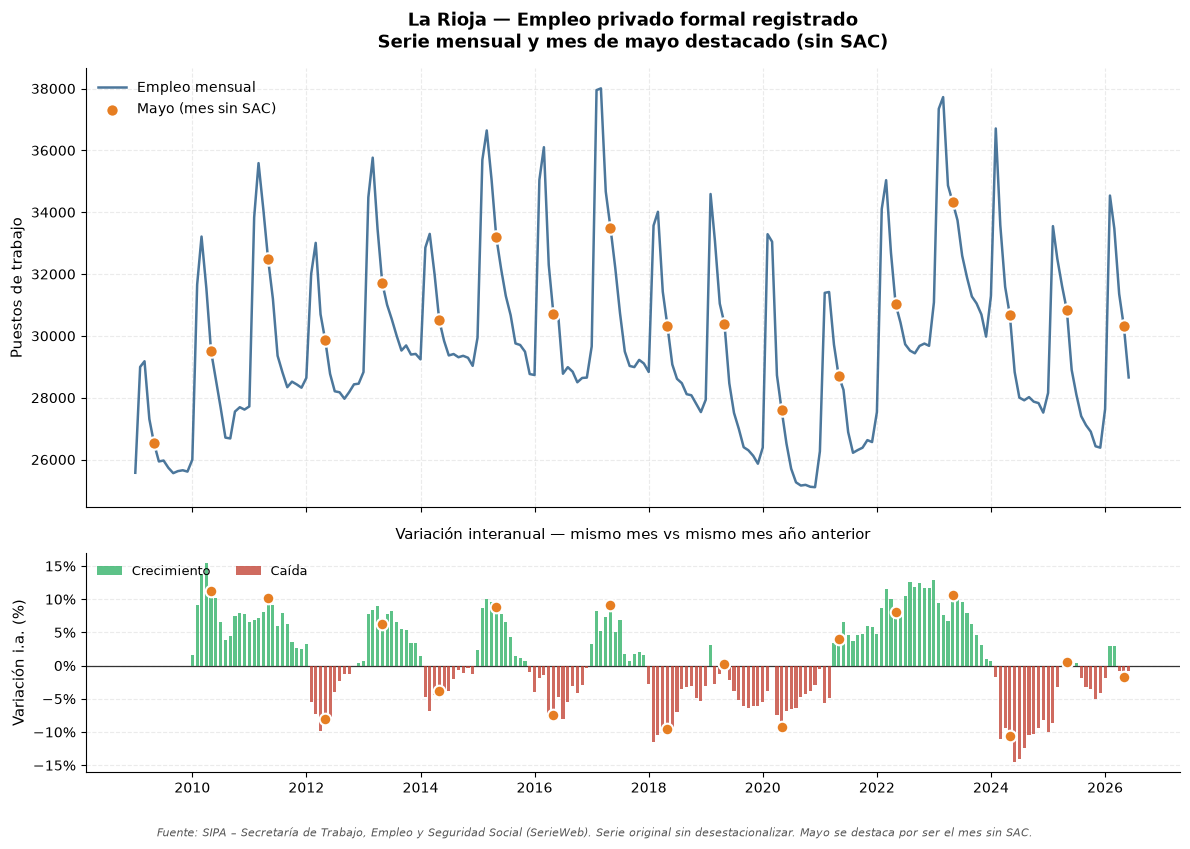


💾 empleo_formal_ia_mayo.png


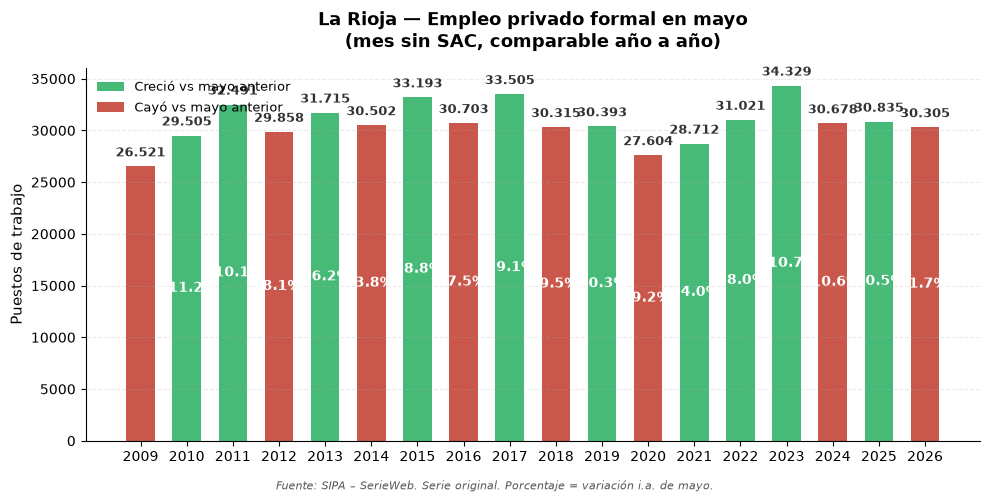

💾 empleo_formal_mayo_comparativo.png

💾 CSVs exportados

📌 RESUMEN EJECUTIVO — LA RIOJA

▶ Último mes: Jun-2026
   Empleo: 28.656 puestos
   i.a.:   -0.84%

▶ Mayo 2026 (mes limpio, sin SAC):
   Empleo: 30.305 puestos
   i.a.:   -1.72%

▶ Pico histórico: Mar-2017 — 38.006 puestos
   Caída desde el pico: -24.60% (-9.350 puestos)

▶ Últimos 5 mayos:
   Mayo 2022: 31.021 puestos  (+8.04%)
   Mayo 2023: 34.329 puestos  (+10.66%)
   Mayo 2024: 30.678 puestos  (-10.64%)
   Mayo 2025: 30.835 puestos  (+0.51%)
   Mayo 2026: 30.305 puestos  (-1.72%)


In [17]:
# ============================================================
# Empleo privado formal La Rioja — v4 (parser definitivo)
# ============================================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx'

MESES_ES = {'ene':1,'feb':2,'mar':3,'abr':4,'may':5,'jun':6,
            'jul':7,'ago':8,'sep':9,'set':9,'oct':10,'nov':11,'dic':12}

def parse_fecha(x):
    if x is None:
        return pd.NaT
    if isinstance(x, float) and pd.isna(x):
        return pd.NaT
    # Timestamp nativo
    if isinstance(x, pd.Timestamp):
        return x
    # datetime.datetime o date
    if hasattr(x, 'year') and hasattr(x, 'month'):
        try:
            return pd.Timestamp(x.year, x.month, 1)
        except Exception:
            return pd.NaT
    s = str(x).strip()
    # Limpiar asteriscos (jun-21*), espacios, etc.
    s_clean = re.sub(r'[*\s]+', '', s).lower()
    # 1) Formato español: "abr-15", "abr-2015", "abr/15", "abr.2015"
    m = re.match(r'^([a-záéíóú]{3,})[\-\/\.](\d{2,4})$', s_clean)
    if m:
        mes_abbr = m.group(1)[:3]
        anio_raw = m.group(2)
        mes = MESES_ES.get(mes_abbr)
        if mes and anio_raw.isdigit():
            anio = int(anio_raw)
            if anio < 100:
                anio += 2000
            return pd.Timestamp(year=anio, month=mes, day=1)
    # 2) ISO o año solo: "2015-04-01", "2015-04", "2015"
    try:
        return pd.Timestamp(s_clean)
    except Exception:
        return pd.NaT

# --- Leer ---
raw = pd.read_excel(ruta, sheet_name='serie_original', header=0)
raw = raw.rename(columns={raw.columns[0]: 'provincia'})

# --- Transponer y parsear ---
df = raw.set_index('provincia').T
df.index = pd.DatetimeIndex([parse_fecha(x) for x in df.index])
df.index.name = 'fecha'

nat = df.index.isna().sum()
print(f'📅 Fechas OK: {len(df) - nat} / {len(df)}  (NaT: {nat})')
df = df[~df.index.isna()].sort_index()

print(f'✅ Rango: {df.index.min().strftime("%Y-%m")} → {df.index.max().strftime("%Y-%m")}')

# --- SANITY CHECK: años fuera de rango razonable ---
anios = sorted(df.index.year.unique().tolist())
print(f'   Años únicos ({len(anios)}): {anios[0]}...{anios[-1]}')
anios_raros = [a for a in anios if a < 2005 or a > 2030]
if anios_raros:
    print(f'   ⚠️ Años raros: {anios_raros}')
    print(f'      Filas afectadas: {df.index[df.index.year.isin(anios_raros)].tolist()[:5]}')
else:
    print('   ✅ Todos los años entre 2005 y 2030')

# --- La Rioja en puestos ---
lr = pd.to_numeric(df['La Rioja'], errors='coerce').dropna() * 1000
lr = lr.sort_index()
print(f'\n📈 La Rioja: {len(lr)} meses')
print(f'   Rango final: {lr.index.min().strftime("%Y-%m")} → {lr.index.max().strftime("%Y-%m")}')
print(f'   Últimos 6 valores:')
print(lr.tail(6).to_string())

# --- Serie mensual + i.a. ---
mensual = pd.DataFrame({'empleo': lr})
mensual['var_ia_%'] = (lr.pct_change(12) * 100).round(2)

# --- MAYOS ---
mayos = mensual[mensual.index.month == 5].copy()
mayos.index = mayos.index.year
mayos = mayos.rename(columns={'empleo':'empleo_mayo',
                              'var_ia_%':'var_ia_mayo_%'})

print('\n' + '='*72)
print('📊 SERIE DE MAYOS — mes limpio (sin SAC)')
print('='*72)
print(mayos.to_string())

print('\n📈 Últimos 18 meses (i.a. mensual):')
t18 = mensual[['empleo','var_ia_%']].tail(18).copy()
t18.index = t18.index.strftime('%Y-%m')
print(t18.to_string())

# --- GRÁFICO 1: Panel doble ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8.5),
                                gridspec_kw={'height_ratios':[2, 1]},
                                sharex=True)

ax1.plot(mensual.index, mensual['empleo'], color='#2c5f8a',
         linewidth=1.8, alpha=0.85, zorder=2, label='Empleo mensual')

mayos_fechas = [pd.Timestamp(f'{y}-05-01') for y in mayos.index]
ax1.scatter(mayos_fechas, mayos['empleo_mayo'],
            color='#e67e22', s=80, zorder=4,
            edgecolor='white', linewidth=1.5,
            label='Mayo (mes sin SAC)')

ax1.set_ylabel('Puestos de trabajo', fontsize=11)
ax1.set_title('La Rioja — Empleo privado formal registrado\n'
              'Serie mensual y mes de mayo destacado (sin SAC)',
              fontsize=13, fontweight='bold', pad=15)
ax1.grid(True, alpha=0.25, linestyle='--')
ax1.legend(loc='upper left', fontsize=10, frameon=False)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)

var_plot = mensual['var_ia_%'].dropna()
colores = ['#27ae60' if v >= 0 else '#c0392b' for v in var_plot.values]
ax2.bar(var_plot.index, var_plot.values, width=20,
        color=colores, alpha=0.75, zorder=3)
ax2.scatter(mayos_fechas, mayos['var_ia_mayo_%'].values,
            color='#e67e22', s=70, zorder=5,
            edgecolor='white', linewidth=1.5)

ax2.axhline(0, color='#333', linewidth=0.9, zorder=2)
ax2.set_ylabel('Variación i.a. (%)', fontsize=11)
ax2.set_title('Variación interanual — mismo mes vs mismo mes año anterior',
              fontsize=11, pad=10)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.grid(True, alpha=0.25, linestyle='--', axis='y')
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

leyenda = [Patch(facecolor='#27ae60', alpha=0.75, label='Crecimiento'),
           Patch(facecolor='#c0392b', alpha=0.75, label='Caída')]
ax2.legend(handles=leyenda, loc='upper left', fontsize=9,
           frameon=False, ncol=2)

fig.text(0.5, 0.01,
         'Fuente: SIPA – Secretaría de Trabajo, Empleo y Seguridad Social (SerieWeb). '
         'Serie original sin desestacionalizar. Mayo se destaca por ser el mes sin SAC.',
         ha='center', fontsize=8, color='#555', style='italic')

plt.tight_layout(rect=[0, 0.04, 1, 1])
out_fig = RAIZ / 'informe' / 'figuras' / 'empleo_formal_ia_mayo.png'
out_fig.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f'\n💾 {out_fig.name}')

# --- GRÁFICO 2: mayos comparativo ---
fig2, ax = plt.subplots(figsize=(10, 5))
emps_may = mayos['empleo_mayo']
vars_may = mayos['var_ia_mayo_%']
colores_may = ['#27ae60' if (pd.notna(v) and v >= 0) else '#c0392b' for v in vars_may]
bars = ax.bar(mayos.index, emps_may, color=colores_may, alpha=0.85, width=0.62)

for b, v, ia in zip(bars, emps_may, vars_may):
    ax.text(b.get_x() + b.get_width()/2, v + emps_may.max()*0.02,
            f'{int(v):,}'.replace(',', '.'),
            ha='center', va='bottom', fontsize=9, fontweight='bold', color='#333')
    if pd.notna(ia):
        ax.text(b.get_x() + b.get_width()/2, v/2,
                f'{ia:+.1f}%', ha='center', va='center',
                fontsize=10, fontweight='bold', color='white')

ax.set_title('La Rioja — Empleo privado formal en mayo\n'
             '(mes sin SAC, comparable año a año)',
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Puestos de trabajo', fontsize=11)
ax.set_xticks(mayos.index)
ax.grid(True, alpha=0.25, linestyle='--', axis='y')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.legend(handles=[Patch(facecolor='#27ae60', alpha=0.85, label='Creció vs mayo anterior'),
                   Patch(facecolor='#c0392b', alpha=0.85, label='Cayó vs mayo anterior')],
          loc='upper left', fontsize=9.5, frameon=False)
fig2.text(0.5, 0.01,
          'Fuente: SIPA – SerieWeb. Serie original. Porcentaje = variación i.a. de mayo.',
          ha='center', fontsize=8, color='#555', style='italic')
plt.tight_layout(rect=[0, 0.03, 1, 1])
out_fig2 = RAIZ / 'informe' / 'figuras' / 'empleo_formal_mayo_comparativo.png'
plt.savefig(out_fig2, dpi=150, bbox_inches='tight')
plt.show()
print(f'💾 {out_fig2.name}')

# --- Exportar ---
mensual.to_csv(RAIZ / 'data' / 'processed' / 'empleo_formal_ia_mensual.csv',
               encoding='utf-8-sig')
mayos.to_csv(RAIZ / 'data' / 'processed' / 'empleo_formal_mayos.csv',
             encoding='utf-8-sig')
print('\n💾 CSVs exportados')

# --- RESUMEN EJECUTIVO ---
print('\n' + '='*72)
print('📌 RESUMEN EJECUTIVO — LA RIOJA')
print('='*72)

ult = mensual.iloc[-1]
print(f'\n▶ Último mes: {mensual.index[-1].strftime("%b-%Y")}')
print(f'   Empleo: {int(ult["empleo"]):,} puestos'.replace(',', '.'))
print(f'   i.a.:   {ult["var_ia_%"]:+.2f}%')

if len(mayos) >= 1:
    ym = mayos.index[-1]
    row = mayos.iloc[-1]
    print(f'\n▶ Mayo {ym} (mes limpio, sin SAC):')
    print(f'   Empleo: {int(row["empleo_mayo"]):,} puestos'.replace(',', '.'))
    if pd.notna(row['var_ia_mayo_%']):
        print(f'   i.a.:   {row["var_ia_mayo_%"]:+.2f}%')

pico = lr.max()
pico_f = lr.idxmax().strftime('%b-%Y')
print(f'\n▶ Pico histórico: {pico_f} — {int(pico):,} puestos'.replace(',', '.'))
print(f'   Caída desde el pico: {(ult["empleo"]/pico - 1)*100:+.2f}% '
      f'({int(ult["empleo"]-pico):,} puestos)'.replace(',', '.'))

print('\n▶ Últimos 5 mayos:')
for anio, row in mayos.tail(5).iterrows():
    em = int(row['empleo_mayo'])
    ia = row['var_ia_mayo_%']
    ia_str = f'{ia:+.2f}%' if pd.notna(ia) else 'n/a'
    print(f'   Mayo {anio}: {em:,} puestos  ({ia_str})'.replace(',', '.'))

In [18]:
# ============================================================
# EMPLEO FORMAL LA RIOJA — Genera todos los archivos
#   - CSV mensual con i.a.
#   - CSV desestacionalizada
#   - JSON combo (labels + tendencia + i.a.) para el HTML
# ============================================================
import re, json
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx'
out_dir = RAIZ / 'data' / 'processed'
out_dir.mkdir(parents=True, exist_ok=True)

MESES_ES  = {'ene':1,'feb':2,'mar':3,'abr':4,'may':5,'jun':6,
             'jul':7,'ago':8,'sep':9,'set':9,'oct':10,'nov':11,'dic':12}
MESES_ABR = {1:'Ene',2:'Feb',3:'Mar',4:'Abr',5:'May',6:'Jun',
             7:'Jul',8:'Ago',9:'Sep',10:'Oct',11:'Nov',12:'Dic'}

def parse_fecha(x):
    if x is None or (isinstance(x, float) and pd.isna(x)): return pd.NaT
    if isinstance(x, pd.Timestamp): return x
    if hasattr(x, 'year') and hasattr(x, 'month'):
        try: return pd.Timestamp(x.year, x.month, 1)
        except: return pd.NaT
    s = re.sub(r'[*\s]+', '', str(x).strip()).lower()
    m = re.match(r'^([a-záéíóú]{3,})[\-\/\.](\d{2,4})$', s)
    if m:
        mes = MESES_ES.get(m.group(1)[:3]); a = m.group(2)
        if mes and a.isdigit():
            anio = int(a) + (2000 if int(a) < 100 else 0)
            return pd.Timestamp(year=anio, month=mes, day=1)
    try: return pd.Timestamp(s)
    except: return pd.NaT

def leer_serie(hoja):
    raw = pd.read_excel(ruta, sheet_name=hoja, header=0)
    raw = raw.rename(columns={raw.columns[0]: 'provincia'})
    df = raw.set_index('provincia').T
    df.index = pd.DatetimeIndex([parse_fecha(x) for x in df.index])
    df = df[~df.index.isna()].sort_index()
    lr = pd.to_numeric(df['La Rioja'], errors='coerce').dropna() * 1000
    return lr.sort_index()

# --- 1. Cargar series ---
orig = leer_serie('serie_original')
des  = leer_serie('serie_desestacionalizada')
print(f'✅ Original:          {orig.index.min().strftime("%Y-%m")} → {orig.index.max().strftime("%Y-%m")}')
print(f'✅ Desestacionalizada:{des.index.min().strftime("%Y-%m")} → {des.index.max().strftime("%Y-%m")}')

# --- 2. i.a. mensual ---
ia = (orig.pct_change(12) * 100).round(2)

# --- 3. CSV: mensual con i.a. ---
mensual = pd.DataFrame({
    'empleo': orig,
    'var_ia_%': ia,
}).dropna(subset=['empleo'])
mensual.index.name = 'fecha'
out_mensual = out_dir / 'empleo_formal_mensual.csv'
mensual.to_csv(out_mensual, encoding='utf-8-sig')
print(f'💾 {out_mensual.name}  ({len(mensual)} filas)')

# --- 4. CSV: desestacionalizada ---
des_df = pd.DataFrame({'empleo_desest': des})
des_df.index.name = 'fecha'
out_des = out_dir / 'empleo_formal_desest.csv'
des_df.to_csv(out_des, encoding='utf-8-sig')
print(f'💾 {out_des.name}  ({len(des_df)} filas)')

# --- 5. JSON combo (2022-2026) para el HTML ---
des22 = des[des.index >= '2022-01-01']
ia22  = ia[(ia.index >= '2022-01-01')]

labels = [f'{MESES_ABR[d.month]}-{str(d.year)[2:]}' for d in des22.index]
tendencia = [int(round(v)) for v in des22.values]
ia_vals = [None if pd.isna(ia22.get(d)) else round(float(ia22.get(d)), 2)
           for d in des22.index]

# KPIs para la sección
ult_fecha = orig.index[-1]
ult_orig = orig.iloc[-1]
ult_ia   = ia.iloc[-1]
mayo26 = orig[(orig.index.year == 2026) & (orig.index.month == 5)].iloc[0]
mayo26_ia = ia[(ia.index.year == 2026) & (ia.index.month == 5)].iloc[0]
pico = orig.max()
pico_fecha = orig.idxmax()

json_data = {
    'chart': {
        'labels': labels,
        'tendencia': tendencia,
        'ia': ia_vals
    },
    'kpis': {
        'mes_ultimo':      ult_fecha.strftime('%b-%Y'),
        'empleo_ultimo':   int(ult_orig),
        'ia_ultimo':       round(float(ult_ia), 2),
        'empleo_mayo26':   int(mayo26),
        'ia_mayo26':       round(float(mayo26_ia), 2),
        'pico':            int(pico),
        'pico_fecha':      pico_fecha.strftime('%b-%Y'),
        'caida_pico_pct':  round((ult_orig / pico - 1) * 100, 2),
        'caida_pico_abs':  int(ult_orig - pico),
    }
}

out_json = out_dir / 'empleo_formal_combo.json'
with open(out_json, 'w', encoding='utf-8') as f:
    json.dump(json_data, f, ensure_ascii=False)
print(f'💾 {out_json.name}')

# --- 6. Resumen ---
print('\n' + '='*72)
print('📌 RESUMEN')
print('='*72)
print(f'\n▶ Rango del gráfico: {labels[0]} → {labels[-1]}  ({len(labels)} meses)')
print(f'\n▶ KPIs:')
for k, v in json_data['kpis'].items():
    print(f'   {k}: {v}')

print(f'\n▶ Últimos 6 puntos del gráfico:')
for i in range(-6, 0):
    print(f'   {labels[i]}: tendencia={tendencia[i]:,} · i.a.={ia_vals[i]:+.2f}%'.replace(',', '.'))

print('\n' + '='*72)
print('📋 JSON COMPLETO (copiar el contenido del archivo)')
print('='*72)
print(out_json.read_text(encoding='utf-8'))

✅ Original:          2009-01 → 2026-06
✅ Desestacionalizada:2009-01 → 2026-06
💾 empleo_formal_mensual.csv  (210 filas)
💾 empleo_formal_desest.csv  (210 filas)
💾 empleo_formal_combo.json

📌 RESUMEN

▶ Rango del gráfico: Ene-22 → Jun-26  (54 meses)

▶ KPIs:
   mes_ultimo: Jun-2026
   empleo_ultimo: 28656
   ia_ultimo: -0.84
   empleo_mayo26: 30305
   ia_mayo26: -1.72
   pico: 38006
   pico_fecha: Mar-2017
   caida_pico_pct: -24.6
   caida_pico_abs: -9350

▶ Últimos 6 puntos del gráfico:
   Ene-26: tendencia=28.892 · i.a.=-1.85%
   Feb-26: tendencia=30.134 · i.a.=+2.95%
   Mar-26: tendencia=29.238 · i.a.=+3.00%
   Abr-26: tendencia=29.300 · i.a.=-0.76%
   May-26: tendencia=29.188 · i.a.=-1.72%
   Jun-26: tendencia=28.890 · i.a.=-0.84%

📋 JSON COMPLETO (copiar el contenido del archivo)
{"chart": {"labels": ["Ene-22", "Feb-22", "Mar-22", "Abr-22", "May-22", "Jun-22", "Jul-22", "Ago-22", "Sep-22", "Oct-22", "Nov-22", "Dic-22", "Ene-23", "Feb-23", "Mar-23", "Abr-23", "May-23", "Jun-23", "Jul-

In [19]:
# ============================================================
# Identificar fuente de "Empleo por sector — Promedio 2025"
# ============================================================
import pandas as pd
import numpy as np
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
raw = RAIZ / 'data' / 'raw'

# 1. Listar archivos candidatos
print('=' * 72)
print('📁 ARCHIVOS CANDIDATOS')
print('=' * 72)
candidatos = []
for f in sorted(raw.glob('*.xlsx')):
    nombre = f.name.lower()
    if 'empleo' in nombre:
        candidatos.append(f)
        print(f'   {f.name}')

# 2. Valores actuales del gráfico (los que hay que verificar)
objetivo = {
    'Industria':     8444,
    'Servicios':     7950,
    'Comercio':      6402,
    'Agricultura':   3790,
    'Construcción':  896,
    'Electricidad':  604,
    'Minería':       109,
}
TOTAL_GRAFICO = 28985

print(f'\n📊 Valores actuales del gráfico (TOTAL = {TOTAL_GRAFICO:,}):'.replace(',', '.'))
for k, v in objetivo.items():
    print(f'   {k}: {v:,}'.replace(',', '.'))

# 3. Inspeccionar cada candidato
for f in candidatos:
    print('\n' + '=' * 72)
    print(f'📄 {f.name}')
    print('=' * 72)
    try:
        xl = pd.ExcelFile(f)
        print(f'   Hojas ({len(xl.sheet_names)}): {xl.sheet_names}')
        
        for hoja in xl.sheet_names[:6]:
            try:
                df = pd.read_excel(f, sheet_name=hoja, header=None, nrows=15)
                print(f'\n   --- Hoja: "{hoja}" ---')
                print(f'       Shape (primeras 15 filas): {df.shape}')
                print(f'       Primeras 15 filas x 6 cols:')
                print(df.iloc[:15, :6].to_string())
            except Exception as e:
                print(f'   ⚠️  Error leyendo "{hoja}": {e}')
    except Exception as e:
        print(f'   ⚠️  Error abriendo: {e}')

📁 ARCHIVOS CANDIDATOS
   nacional_serie_empleo_trimestral_7.xlsx
   provinciales_serie_empleo_anual_3.xlsx
   provinciales_serie_empleo_trimestral_2dig_6.xlsx
   provinciales_serie_empleo_trimestral_4dig_7.xlsx
   SerieWeb_EMPLEO_PRIVADO_FORMAL_provincias.xlsx

📊 Valores actuales del gráfico (TOTAL = 28.985):
   Industria: 8.444
   Servicios: 7.950
   Comercio: 6.402
   Agricultura: 3.790
   Construcción: 896
   Electricidad: 604
   Minería: 109

📄 nacional_serie_empleo_trimestral_7.xlsx
   Hojas (12): ['Carátula', 'Indice', 'C1.1', 'C1.2', 'C2.1', 'C2.2', 'C3', 'C4', 'C5', 'C6', 'C7', 'Descriptores de actividad']

   --- Hoja: "Carátula" ---
       Shape (primeras 15 filas): (0, 0)
       Primeras 15 filas x 6 cols:
Empty DataFrame
Columns: []
Index: []

   --- Hoja: "Indice" ---
       Shape (primeras 15 filas): (15, 1)
       Primeras 15 filas x 6 cols:
                                                                                                                              0
0  

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")
c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



   --- Hoja: "Caratula" ---
       Shape (primeras 15 filas): (0, 0)
       Primeras 15 filas x 6 cols:
Empty DataFrame
Columns: []
Index: []

   --- Hoja: "Indice" ---
       Shape (primeras 15 filas): (15, 84)
       Primeras 15 filas x 6 cols:
     0                                                   1         2                    3   4   5
0  NaN  Índice Boletin Trimestral de Empleo por Provincias       NaN                  NaN NaN NaN
1  NaN                                                 NaN       NaN                  NaN NaN NaN
2  NaN                                     Partidos de GBA   Formosa                Salta NaN NaN
3  NaN                                                 NaN       NaN                  NaN NaN NaN
4  NaN                                     Capital Federal     Jujuy             San Juan NaN NaN
5  NaN                                                 NaN       NaN                  NaN NaN NaN
6  NaN                                Resto de Bueno Aires  La Pam

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")
c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



   --- Hoja: "Partidos de GBA" ---
       Shape (primeras 15 filas): (15, 122)
       Primeras 15 filas x 6 cols:
                                                                                                                   0                                              1             2                 3             4             5
0                                                                                                                NaN                                            NaN           NaN  Volver al índice           NaN           NaN
1                                                                                                    PARTIDOS DE GBA                                            NaN           NaN               NaN           NaN           NaN
2   Empleo. Asalariados registrados del sector privado por rama de actividad - Trimestres corridos 1° 1996 - 4° 2025                                            NaN           NaN               NaN           NaN    

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



   --- Hoja: "Resto de Buenos Aires" ---
       Shape (primeras 15 filas): (15, 122)
       Primeras 15 filas x 6 cols:
                                                                                                                   0                                              1             2                 3             4             5
0                                                                                                                NaN                                            NaN           NaN  Volver al índice           NaN           NaN
1                                                                                              RESTO DE BUENOS AIRES                                            NaN           NaN               NaN           NaN           NaN
2   Empleo. Asalariados registrados del sector privado por rama de actividad - Trimestres corridos 1° 1996 - 4° 2025                                            NaN           NaN               NaN           N

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



   --- Hoja: "Catamarca" ---
       Shape (primeras 15 filas): (15, 122)
       Primeras 15 filas x 6 cols:
                                                                                                                   0                                              1             2                 3             4             5
0                                                                                                                NaN                                            NaN           NaN  Volver al índice           NaN           NaN
1                                                                                                          CATAMARCA                                            NaN           NaN               NaN           NaN           NaN
2   Empleo. Asalariados registrados del sector privado por rama de actividad - Trimestres corridos 1° 1996 - 4° 2025                                            NaN           NaN               NaN           NaN          

In [21]:
# ============================================================
# Diagnóstico: listar todos los xlsx y ver cuál tiene secciones
# ============================================================
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
raw = RAIZ / 'data' / 'raw'

print('=' * 72)
print('📁 TODOS LOS .XLSX EN data/raw/')
print('=' * 72)

for f in sorted(raw.glob('*.xlsx')):
    print(f'\n📄 {f.name}')
    print(f'   Tamaño: {f.stat().st_size/1024:.0f} KB')
    try:
        xl = pd.ExcelFile(f)
        hojas = xl.sheet_names
        print(f'   Hojas ({len(hojas)}): {hojas[:8]}{"..." if len(hojas) > 8 else ""}')
        
        # Si tiene hoja "La Rioja", inspeccionar primeras filas
        if 'La Rioja' in hojas:
            df = pd.read_excel(f, sheet_name='La Rioja', header=None, nrows=12)
            print(f'   ➤ Hoja "La Rioja" — primeras 12 filas x 3 cols:')
            for i in range(min(12, len(df))):
                vals = df.iloc[i, :3].tolist()
                print(f'      [{i}] {vals}')
    except Exception as e:
        print(f'   ⚠️  Error: {type(e).__name__}: {str(e)[:100]}')

# Buscar también otros archivos con extensión rara
print('\n' + '=' * 72)
print('📁 OTROS ARCHIVOS EN data/raw/ (no xlsx)')
print('=' * 72)
for f in sorted(raw.iterdir()):
    if f.suffix.lower() != '.xlsx':
        print(f'   {f.name}  ({f.stat().st_size/1024:.0f} KB)')

📁 TODOS LOS .XLSX EN data/raw/

📄 actividad_ied.xlsx
   Tamaño: 5106 KB
   Hojas (64): ['Indice', '1.1 OyD real', '1.1.1 OyD real BASE 2004', '1.2 OyD real s.e.', '1.2.1 OyD real s.e. BASE 2004', '1.3 PIB real x sector', '1.3.1 PIB real x sector BASE 04', '1.3.2 VAB real x rama 2004']...

📄 Internet Accesos Tecnologias Provincias.xlsx
   Tamaño: 68 KB
   Hojas (1): ['Sheet1']

📄 nacional_serie_empleo_trimestral_7.xlsx
   Tamaño: 3315 KB
   Hojas (12): ['Carátula', 'Indice', 'C1.1', 'C1.2', 'C2.1', 'C2.2', 'C3', 'C4']...

📄 nacional_serie_empresas_2.xlsx
   Tamaño: 425 KB
   Hojas (14): ['Carátula', 'Metodologia', 'Indice', 'C 1', 'C 2', 'C 3', 'C 4', 'C 5']...

📄 provinciales_serie_empleo_anual_3.xlsx
   Tamaño: 644 KB
   Hojas (11): ['Carátula', 'Metodología', 'Indice', 'T1', 'T2', 'T3a', 'T3b', 'T3c']...

📄 provinciales_serie_empleo_trimestral_2dig_6.xlsx
   Tamaño: 1430 KB
   Hojas (28): ['Caratula', 'Indice', 'Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires', 'Catamarca

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")


   ➤ Hoja "La Rioja" — primeras 12 filas x 3 cols:
      [0] [nan, nan, nan]
      [1] ['LA RIOJA', nan, nan]
      [2] ['Empleo. Asalariados registrados del sector privado por rama de actividad - Trimestres corridos 1° 1996 - 4° 2025', nan, nan]
      [3] [nan, 'Ramas de actividad', '1º Trim 1996']
      [4] [nan, nan, nan]
      [5] ['A', 'AGRICULTURA, GANADERIA, CAZA Y SILVICULTURA', 1211]
      [6] [1, 'Agricultura y ganaderia', 's.d.']
      [7] [2, 'Silvicultura, extracción de madera', 's.d.']
      [8] ['B', 'PESCA Y SERVICIOS CONEXOS', 's.d.']
      [9] [5, 'Pesca y actividades relacionadas con la pesca', 's.d.']
      [10] ['C', 'EXPLOTACION  DE  MINAS  Y  CANTERAS', 83]
      [11] [11, 'Extraccion de petroleo crudo y gas natural', 's.d.']

📄 provinciales_serie_empleo_trimestral_4dig_7.xlsx
   Tamaño: 4281 KB
   Hojas (28): ['Caratula', 'Indice', 'GBA', 'CABA', 'Resto de Buenos Aires', 'Catamarca', 'Córdoba', 'Corrientes']...
   ➤ Hoja "La Rioja" — primeras 12 filas x 3 cols:


c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")


   Hojas (29): ['Carátula', 'Indice', 'Metodología', 'Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires', 'Catamarca', 'Cordoba']...
   ➤ Hoja "La Rioja" — primeras 12 filas x 3 cols:
      [0] [nan, nan, nan]
      [1] ['LA RIOJA', nan, nan]
      [2] ['Empresas del sector privado por rama de actividad - Activas en cada año', nan, nan]
      [3] [nan, 'Ramas de actividad', 1996]
      [4] [nan, nan, nan]
      [5] ['A', 'AGRICULTURA, GANADERIA, CAZA Y SILVICULTURA', 294]
      [6] [1, 'Agricultura y ganaderia', 's.d.']
      [7] [2, 'Silvicultura, extracción de madera', 's.d.']
      [8] ['B', 'PESCA Y SERVICIOS CONEXOS', 's.d.']
      [9] [5, 'Pesca y actividades relacionadas con la pesca', 's.d.']
      [10] ['C', 'EXPLOTACION  DE  MINAS  Y  CANTERAS', 12]
      [11] [11, 'Extraccion de petroleo crudo y gas natural', 's.d.']

📄 provinciales_serie_empresas1_2.xlsx
   Tamaño: 585 KB


c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")


   Hojas (29): ['Carátula', 'Indice', 'Metodología', 'Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires', 'Catamarca', 'Cordoba']...
   ➤ Hoja "La Rioja" — primeras 12 filas x 3 cols:
      [0] [nan, nan, nan]
      [1] ['LA RIOJA', nan, nan]
      [2] ['Empresas del sector privado por rama de actividad - Activas en cada año', nan, nan]
      [3] [nan, 'Ramas de actividad', 1996]
      [4] [nan, nan, nan]
      [5] ['A', 'AGRICULTURA, GANADERIA, CAZA Y SILVICULTURA', 294]
      [6] [1, 'Agricultura y ganaderia', 's.d.']
      [7] [2, 'Silvicultura, extracción de madera', 's.d.']
      [8] ['B', 'PESCA Y SERVICIOS CONEXOS', 's.d.']
      [9] [5, 'Pesca y actividades relacionadas con la pesca', 's.d.']
      [10] ['C', 'EXPLOTACION  DE  MINAS  Y  CANTERAS', 12]
      [11] [11, 'Extraccion de petroleo crudo y gas natural', 's.d.']

📄 provinciales_serie_empresas2_2.xlsx
   Tamaño: 554 KB
   Hojas (10): ['Carátula', 'Metodología', 'Indice', 'T1', 'T2', 'T3', 'T4', 'T5']...

📄 prov

In [22]:
# ============================================================
# Empleo por sector — La Rioja — desde 2dig_6
# Comparación con el gráfico actual
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_2dig_6.xlsx'

# --- 1. Leer hoja "La Rioja" con header en fila 3 ---
df = pd.read_excel(ruta, sheet_name='La Rioja', header=3)
df.columns = [str(c).strip() for c in df.columns]
print('📋 Columnas (primeras 6):', df.columns[:6].tolist())
print('📋 Columnas (últimas 4):', df.columns[-4:].tolist())

# Renombrar columnas 0 y 1
df = df.rename(columns={df.columns[0]: 'seccion', df.columns[1]: 'descripcion'})

# --- 2. Detectar columnas de trimestres 2025 ---
cols_2025 = [c for c in df.columns if '2025' in str(c)]
print(f'\n📅 Trimestres 2025 detectados: {cols_2025}')

# --- 3. Filtrar solo secciones con letra (A, B, C...) ---
df['seccion_str'] = df['seccion'].astype(str).str.strip()
df_secciones = df[df['seccion_str'].str.fullmatch(r'[A-Z]')].copy()
print(f'\n📊 Secciones CIIU encontradas: {len(df_secciones)}')

# --- 4. Calcular promedio de los 4 trimestres de 2025 ---
resultado = []
for _, row in df_secciones.iterrows():
    vals = []
    for c in cols_2025:
        v = row[c]
        if pd.notna(v) and str(v).strip() not in ['s.d.', 'sd', '']:
            try:
                vals.append(float(v))
            except:
                pass
    if vals:
        resultado.append({
            'seccion': row['seccion_str'],
            'descripcion': str(row['descripcion']).strip(),
            'empleo_prom_2025': round(np.mean(vals), 0),
            'n_trimestres': len(vals),
        })

tabla = pd.DataFrame(resultado)
tabla = tabla.sort_values('empleo_prom_2025', ascending=False)

print('\n' + '=' * 100)
print('📊 EMPLEO POR SECCIÓN CIIU — La Rioja, promedio 2025')
print('=' * 100)
print(tabla.to_string(index=False))

# --- 5. Agrupación según las categorías del dashboard ---
print('\n' + '=' * 100)
print('📊 AGRUPACIÓN SEGÚN CATEGORÍAS DEL DASHBOARD')
print('=' * 100)

def buscar(*palabras):
    m = tabla[tabla['descripcion'].str.upper().str.contains('|'.join(palabras), na=False)]
    return int(m['empleo_prom_2025'].sum())

# Mapeo según secciones CIIU Rev.3
categorias = {
    'Agricultura':    buscar('AGRICULTURA'),
    'Minería':        buscar('MINAS', 'CANTERAS'),
    'Industria':      buscar('INDUSTRIA MANUFACTURERA'),
    'Electricidad':   buscar('ELECTRICIDAD', 'GAS', 'AGUA'),
    'Construcción':   buscar('CONSTRUCCION'),
    'Comercio':       buscar('COMERCIO'),
    'Servicios':      buscar('HOTEL', 'RESTAURANT', 'TRANSPORTE',
                             'INTERMEDIACION', 'INMOBILIARIA',
                             'ADMINISTRACION', 'EDUCACION', 'SALUD',
                             'SERVICIOS SOCIALES', 'OTRAS ACTIVIDADES'),
}
total = sum(categorias.values())

print(f'\n{"Categoría":<16} {"Calculado":>12} {"Gráfico":>12} {"Dif":>10}')
print('-' * 60)
graf = {'Industria':8444, 'Servicios':7950, 'Comercio':6402,
        'Agricultura':3790, 'Construcción':896,
        'Electricidad':604, 'Minería':109}
for k, v in categorias.items():
    g = graf.get(k, 0)
    d = int(v) - g
    marca = '✅' if abs(d) < 50 else ('🟡' if abs(d) < 300 else '🔴')
    print(f'{k:<16} {int(v):>12,} {g:>12,} {d:>+10,}  {marca}'.replace(',', '.'))

print('-' * 60)
print(f'{"TOTAL":<16} {int(total):>12,} {sum(graf.values()):>12,} '
      f'{int(total)-sum(graf.values()):>+10,}'.replace(',', '.'))

# --- 6. Ver TODAS las secciones para no perder ninguna ---
print('\n' + '=' * 100)
print('📋 SECCIONES CIIU COMPLETAS (para verificar agrupación)')
print('=' * 100)
for _, r in tabla.iterrows():
    print(f"  {r['seccion']} - {r['descripcion'][:70]:<70} {int(r['empleo_prom_2025']):>10,}".replace(',', '.'))

📋 Columnas (primeras 6): ['Unnamed: 0', 'Ramas de actividad', '1º Trim 1996', '2º Trim 1996', '3º Trim 1996', '4º Trim 1996']
📋 Columnas (últimas 4): ['1° Trim 2025', '2° Trim 2025', '3° Trim 2025', '4° Trim 2025']

📅 Trimestres 2025 detectados: ['1° Trim 2025', '2° Trim 2025', '3° Trim 2025', '4° Trim 2025']

📊 Secciones CIIU encontradas: 14

📊 EMPLEO POR SECCIÓN CIIU — La Rioja, promedio 2025
seccion                                                    descripcion  empleo_prom_2025  n_trimestres
      D                                        INDUSTRIA MANUFACTURERA            8546.0             4
      G                           COMERCIO AL POR MAYOR Y AL POR MENOR            6721.0             4
      A                    AGRICULTURA, GANADERIA, CAZA Y SILVICULTURA            4946.0             4
      K           SERVICIOS INMOBILIARIOS, EMPRESARIALES Y DE ALQUILER            1747.0             4
      N                                  SERVICIOS SOCIALES Y DE SALUD            1625.

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")
C:\Users\HP\AppData\Local\Temp\ipykernel_10300\757970038.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['seccion_str'] = df['seccion'].astype(str).str.strip()


In [23]:
# ============================================================
# Comparar provinciales_serie_empleo_anual_3 vs trimestral_2dig_6
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
raw = RAIZ / 'data' / 'raw'

# ============================================================
# PARTE 1: Inspeccionar el archivo ANUAL
# ============================================================
ruta_anual = raw / 'provinciales_serie_empleo_anual_3.xlsx'
print('=' * 72)
print(f'📄 {ruta_anual.name}')
print('=' * 72)

xl = pd.ExcelFile(ruta_anual)
print(f'\n📑 Hojas ({len(xl.sheet_names)}): {xl.sheet_names}')

# Inspeccionar cada hoja (primeras 8 filas)
for hoja in xl.sheet_names:
    print(f'\n--- Hoja: "{hoja}" ---')
    try:
        df = pd.read_excel(ruta_anual, sheet_name=hoja, header=None, nrows=8)
        print(f'   Shape (parcial): {df.shape}')
        print(df.iloc[:8, :6].to_string())
    except Exception as e:
        print(f'   ⚠️  {e}')

# ============================================================
# PARTE 2: Buscar dónde está "La Rioja" y la estructura de datos
# ============================================================
print('\n' + '=' * 72)
print('🔎 BUSCANDO HOJA CON DATOS DE LA RIOJA')
print('=' * 72)

for hoja in xl.sheet_names:
    try:
        df = pd.read_excel(ruta_anual, sheet_name=hoja, header=None, nrows=15)
        # Ver si menciona La Rioja
        texto = ' '.join(df.astype(str).values.flatten()).upper()
        if 'LA RIOJA' in texto:
            print(f'\n✅ Hoja "{hoja}" menciona La Rioja')
            print(df.iloc[:15, :6].to_string())
            break
    except Exception:
        pass

📄 provinciales_serie_empleo_anual_3.xlsx

📑 Hojas (11): ['Carátula', 'Metodología', 'Indice', 'T1', 'T2', 'T3a', 'T3b', 'T3c', 'T4a', 'T4b', 'T5']

--- Hoja: "Carátula" ---
   Shape (parcial): (0, 0)
Empty DataFrame
Columns: []
Index: []

--- Hoja: "Metodología" ---
   Shape (parcial): (8, 1)
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                0
0                                                                                                               

In [24]:
# ============================================================
# Empleo por sector — La Rioja desde archivo ANUAL
#   T1: IV Trim 2025 (snapshot)
#   T4b: Promedio anual 2025
#   T5: Serie histórica 1996-2025 en miles
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_anual_3.xlsx'

# ---------- T1: IV Trim 2025 ----------
print('=' * 90)
print('📄 T1 — Empleo por sector, IV Trimestre 2025')
print('=' * 90)

t1 = pd.read_excel(ruta, sheet_name='T1', header=1)
t1.columns = [str(c).strip() for c in t1.columns]
print('Columnas:', t1.columns.tolist())
print()

lr_t1 = t1[t1.iloc[:, 0].astype(str).str.strip().str.upper() == 'LA RIOJA']
print('Fila de La Rioja en T1:')
if not lr_t1.empty:
    for col in t1.columns:
        val = lr_t1.iloc[0][col]
        if pd.notna(val):
            print(f'   {col:<45} {val}')

# ---------- T4b: Promedio anual 2025 ----------
print('\n' + '=' * 90)
print('📄 T4b — Empleo por sector y tamaño, promedio anual 2025')
print('=' * 90)

t4b = pd.read_excel(ruta, sheet_name='T4b', header=1)
t4b.columns = [str(c).strip() for c in t4b.columns]
print('Columnas (primeras 10):', t4b.columns[:10].tolist())
# La Rioja no está en filas, hay que buscarla
print('\nPrimeras filas de T4b:')
print(t4b.iloc[:15, :6].to_string())

# ---------- T5: Serie histórica ----------
print('\n' + '=' * 90)
print('📄 T5 — Puestos por sector, promedios anuales 1996-2025 (en miles)')
print('=' * 90)

t5 = pd.read_excel(ruta, sheet_name='T5', header=1)
t5.columns = [str(c).strip() for c in t5.columns]
print('Columnas (primeras 8):', t5.columns[:8].tolist())
print(f'Shape: {t5.shape}')

# La Rioja está como subfila dentro de cada sector
# Estructura: fila "Partidos de GBA" seguida de Agricultura, Minería, Industria, Comercio, Servicios
# Después fila "Capital Federal" seguida de sus sectores, etc.
# Hay que recorrer hasta encontrar "La Rioja" y extraer sus sectores

provincias = ['Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires',
              'Catamarca', 'Córdoba', 'Corrientes', 'Chaco', 'Chubut',
              'Entre Ríos', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja',
              'Mendoza', 'Misiones', 'Neuquén', 'Río Negro', 'Salta',
              'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fe',
              'Santiago del Estero', 'Tucumán', 'Tierra del Fuego']

# Encontrar La Rioja
for i, row in t5.iterrows():
    v = str(row.iloc[0]).strip()
    if v.upper() == 'LA RIOJA':
        print(f'\n✅ La Rioja en fila {i}')
        print(f'\nFila de La Rioja (valores 1996-2025 en miles):')
        print(row.to_string())
        break
else:
    print('\n⚠️  No se encontró "La Rioja" como fila propia. Estructura diferente.')
    # Ver qué hay entre las filas 1-100
    print('\nPrimeras 60 filas (col 0) para diagnóstico:')
    for i, row in t5.head(60).iterrows():
        v = str(row.iloc[0]).strip()
        if v and v != 'nan':
            print(f'   [{i}] {v}')

📄 T1 — Empleo por sector, IV Trimestre 2025
Columnas: ['Provincia', 'Agricultura, ganadería y pesca', 'Minería y petroleo', 'Industria', 'Electricidad, gas y agua', 'Construcción', 'Comercio', 'Servicios', 'Total']

Fila de La Rioja en T1:
   Provincia                                     La Rioja
   Agricultura, ganadería y pesca                3191.0
   Minería y petroleo                            84.0
   Industria                                     7974.0
   Electricidad, gas y agua                      861.0
   Construcción                                  1063.0
   Comercio                                      6742.0
   Servicios                                     8528.0
   Total                                         28443.0

📄 T4b — Empleo por sector y tamaño, promedio anual 2025
Columnas (primeras 10): ['Unnamed: 0', 'Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires', 'Catamarca', 'Córdoba', 'Corrientes', 'Chaco', 'Chubut', 'Entre Ríos']

Primeras filas de T4b:
  

In [25]:
# ============================================================
# Empleo por sector — La Rioja — Serie completa desde T5
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_anual_3.xlsx'

# ---------- 1. Inspeccionar estructura completa de T5 ----------
t5 = pd.read_excel(ruta, sheet_name='T5', header=1)
t5.columns = [str(c).strip() for c in t5.columns]
print(f'📄 T5: {t5.shape}')
print(f'   Columnas: {t5.columns.tolist()[:5]} ... {t5.columns.tolist()[-3:]}')

print('\n🔎 Filas 90-110 de T5 (para ver La Rioja y los sectores):')
for i in range(90, min(110, len(t5))):
    v = str(t5.iloc[i, 0]).strip()
    if v and v != 'nan':
        # Ver valores de 2022, 2023, 2024, 2025
        fila = t5.iloc[i]
        vals = []
        for anio in [2022, 2023, 2024, 2025]:
            if str(anio) in t5.columns:
                vals.append(f'{anio}={fila[str(anio)]:.1f}' if pd.notna(fila[str(anio)]) else f'{anio}=NaN')
        print(f'   [{i}] {v:<35} {" | ".join(vals)}')

# ---------- 2. Extraer La Rioja + sectores ----------
print('\n' + '=' * 90)
print('📊 LA RIOJA — Sectores 2022-2025 (miles de puestos)')
print('=' * 90)

anios = ['2022', '2023', '2024', '2025']
filas_lr = []
capturar = False
for i, row in t5.iterrows():
    v = str(row.iloc[0]).strip()
    if v.upper() == 'LA RIOJA':
        capturar = True
        filas_lr.append(('Total', i, row))
        continue
    if capturar:
        if v and v != 'nan' and any(p in v for p in ['Partidos', 'Capital', 'Resto', 'Catamarca', 'Córdoba']):
            break
        if v and v != 'nan':
            filas_lr.append((v, i, row))

print(f'\nFilas capturadas para La Rioja: {len(filas_lr)}')
for nombre, idx, row in filas_lr:
    vals = []
    for a in anios:
        if a in t5.columns:
            val = row[a]
            vals.append(f'{val:>8.2f}' if pd.notna(val) else f'{"NaN":>8}')
        else:
            vals.append(f'{"-":>8}')
    print(f'   [{idx}] {nombre:<35} {" ".join(vals)}')

# ---------- 3. Comparación con el gráfico actual ----------
print('\n' + '=' * 90)
print('📊 COMPARACIÓN con el gráfico del dashboard')
print('=' * 90)

graf_actual = {
    'Industria': 8444, 'Servicios': 7950, 'Comercio': 6402,
    'Agricultura': 3790, 'Construcción': 896,
    'Electricidad': 604, 'Minería': 109,
}
print(f'\n{"Sector":<20} {"Gráfico":>10} {"T1 IV-T25":>10} {"Dif":>10}')
print('-' * 55)
t1_lr = {
    'Industria': 7974, 'Servicios': 8528, 'Comercio': 6742,
    'Agricultura': 3191, 'Construcción': 1063,
    'Electricidad': 861, 'Minería': 84,
}
for k in graf_actual:
    dif = t1_lr[k] - graf_actual[k]
    print(f'{k:<20} {graf_actual[k]:>10,} {t1_lr[k]:>10,} {dif:>+10,}'.replace(',', '.'))

print('-' * 55)
print(f'{"TOTAL":<20} {sum(graf_actual.values()):>10,} {sum(t1_lr.values()):>10,} '
      f'{sum(t1_lr.values())-sum(graf_actual.values()):>+10,}'.replace(',', '.'))

# ---------- 4. Verificar coherencia T5 vs T1 ----------
print('\n' + '=' * 90)
print('🔎 Verificación: T5 (2025) vs T1 (IV trim 2025)')
print('=' * 90)
print(f'T5 total La Rioja 2025: 31.067')
print(f'T1 total La Rioja IV-T25: 28.443')
print(f'Diferencia: 2.624  (esperable: promedio anual > IV trim)')

# ---------- 5. Exportar ----------
print('\n📌 Recomendación:')
print('   ➤ Usar T1 para el gráfico "Empleo por sector" (IV Trim 2025).')
print('   ➤ Usar T5 para calcular variaciones 2022→2025 por sector.')

📄 T5: (203, 31)
   Columnas: ['Provincia en la que declara empleo', '1996', '1997', '1998', '1999'] ... ['2023', '2024', '2025']

🔎 Filas 90-110 de T5 (para ver La Rioja y los sectores):
   [90] Minería y petróleo                  2022=0.6 | 2023=0.7 | 2024=0.7 | 2025=0.7
   [91] Industria                           2022=5.3 | 2023=5.5 | 2024=5.5 | 2025=5.2
   [92] Comercio                            2022=11.3 | 2023=11.9 | 2024=12.1 | 2025=12.6
   [93] Servicios                           2022=13.7 | 2023=14.3 | 2024=13.6 | 2025=13.4
   [94] Electricidad, gas y agua            2022=1.8 | 2023=1.9 | 2024=1.9 | 2025=1.9
   [95] Construcción                        2022=3.1 | 2023=4.1 | 2024=2.9 | 2025=2.6
   [96] La Rioja                            2022=32.9 | 2023=35.5 | 2024=32.2 | 2025=31.1
   [97] Agricultura, ganadería y pesca      2022=5.0 | 2023=5.6 | 2024=5.2 | 2025=4.9
   [98] Minería y petróleo                  2022=0.1 | 2023=0.2 | 2024=0.1 | 2025=0.1
   [99] Industria          

In [1]:
# ============================================================
# Rastrear: 102 empresas EC / 3.255 total provincial = 3,13%
# Fuente: provinciales_serie_empresas3_2.xlsx, hoja La Rioja
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empresas3_2.xlsx'

# --- 1. Leer hoja "La Rioja" ---
df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()

# --- 2. Filtrar solo CIIU de 4 dígitos (evitar secciones con letras) ---
df_4d = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df_4d['ciiu'] = df_4d['ciiu_str'].astype(int)

print(f'📄 {ruta.name}')
print(f'   Filas con CIIU de 4 dígitos: {len(df_4d)}')
print(f'   Columnas disponibles: {[c for c in df.columns if str(c).isdigit()][-5:]}')

# --- 3. Ver los valores de 2024 (último año completo) ---
col_2024 = 2024
print(f'\n📅 Año objetivo: {col_2024}')

if col_2024 in df_4d.columns:
    # Convertir a numérico
    df_4d[col_2024] = pd.to_numeric(df_4d[col_2024], errors='coerce')
    
    # Total provincial = suma de TODAS las empresas de la hoja
    total_prov = df_4d[col_2024].sum()
    
    print(f'\n🔢 Total empresas La Rioja {col_2024}: {int(total_prov):,}'.replace(',', '.'))
    
    # --- 4. Filtrar EC (8 CIIU) ---
    CIIU_EC = {7210, 7220, 7250, 7290, 7300, 7421, 7430, 7499}
    df_ec = df_4d[df_4d['ciiu'].isin(CIIU_EC)].copy()
    total_ec = df_ec[col_2024].sum()
    
    print(f'🎯 Empresas EC {col_2024}: {int(total_ec)}')
    print(f'📊 Share: {total_ec / total_prov * 100:.2f}%')
    
    # --- 5. Desglose por CIIU EC ---
    print(f'\n📋 Desglose por CIIU EC:')
    for _, row in df_ec.iterrows():
        v = row[col_2024]
        if pd.notna(v):
            print(f'   {row["ciiu"]} - {str(row["descripcion"])[:60]:<60} {int(v):>5}')
        else:
            print(f'   {row["ciiu"]} - {str(row["descripcion"])[:60]:<60} {"s.d.":>5}')

    # --- 6. Verificar también años previos para consistencia ---
    print(f'\n📊 Serie histórica EC vs Total (2019-2024):')
    print(f'\n{"Año":<6} {"Total Prov":>12} {"EC (8 CIIU)":>13} {"Share":>8}')
    print('-' * 45)
    for anio in [2019, 2020, 2021, 2022, 2024]:
        if anio in df_4d.columns:
            tp = pd.to_numeric(df_4d[anio], errors='coerce').sum()
            ec = pd.to_numeric(df_ec[anio], errors='coerce').sum()
            sh = (ec / tp * 100) if tp else 0
            print(f'{anio:<6} {int(tp):>12,} {int(ec):>13} {sh:>7.2f}%'.replace(',', '.'))

else:
    print(f'⚠️  No hay columna {col_2024}')
    print(f'   Columnas disponibles: {df_4d.columns.tolist()}')

📄 provinciales_serie_empresas3_2.xlsx
   Filas con CIIU de 4 dígitos: 284
   Columnas disponibles: [2020, 2021, 2022, 2024, 2025]

📅 Año objetivo: 2024

🔢 Total empresas La Rioja 2024: 3.004
🎯 Empresas EC 2024: 102
📊 Share: 3.40%

📋 Desglose por CIIU EC:
   7210 - Servicios de consultores en equipo de informática             s.d.
   7220 - Servicios de consultores en informática y suministros de pro    11
   7250 - Mantenimiento y reparación de maquinaria de oficina, contabi     4
   7290 - Actividades de informática n.c.p.                               13
   7300 - Investigación y desarrollo                                    s.d.
   7421 - Servicios de arquitectura e ingeniería y servicios conexos d    31
   7430 - Servicios de publicidad                                          5
   7499 - Servicios empresariales n.c.p.                                  38

📊 Serie histórica EC vs Total (2019-2024):

Año      Total Prov   EC (8 CIIU)    Share
-----------------------------------------

In [2]:
# ============================================================
# Rastrear el 3.255 y el 3,13% en TODOS los archivos de empresas
# ============================================================
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
raw = RAIZ / 'data' / 'raw'

archivos_empresas = [
    'provinciales_serie_empresas.xlsx',
    'provinciales_serie_empresas1_2.xlsx',
    'provinciales_serie_empresas2_2.xlsx',
    'provinciales_serie_empresas3_2.xlsx',
]

CIIU_EC = {7210, 7220, 7250, 7290, 7300, 7421, 7430, 7499}

for nombre in archivos_empresas:
    ruta = raw / nombre
    if not ruta.exists():
        print(f'⚠️  No existe: {nombre}')
        continue
    
    print('\n' + '=' * 80)
    print(f'📄 {nombre}')
    print('=' * 80)
    
    try:
        xl = pd.ExcelFile(ruta)
        print(f'   Hojas: {xl.sheet_names}')
        
        # Buscar hoja "La Rioja"
        hojas_lr = [h for h in xl.sheet_names if 'rioja' in h.lower()]
        if not hojas_lr:
            print(f'   ⚠️  No hay hoja de La Rioja')
            continue
        
        hoja = hojas_lr[0]
        print(f'   Usando hoja: "{hoja}"')
        
        # Leer crudo para inspeccionar
        df_crudo = pd.read_excel(ruta, sheet_name=hoja, header=None, nrows=10)
        print(f'\n   Primeras filas crudas:')
        print(df_crudo.iloc[:10, :4].to_string())
        
        # Intentar leer con header=3 (típico en empresas.xlsx)
        # y header=6 (típico en empresas3_2.xlsx)
        for header_row in [3, 6]:
            try:
                df = pd.read_excel(ruta, sheet_name=hoja, header=header_row)
                df.columns = [str(c).strip() for c in df.columns]
                
                # Ver si tiene años como columnas
                cols_anio = [c for c in df.columns if c.isdigit() and len(c) == 4]
                if not cols_anio:
                    continue
                
                print(f'\n   ✅ Leyendo con header={header_row}')
                print(f'   Columnas de años: {cols_anio[:3]}...{cols_anio[-3:]}')
                
                # Renombrar col 0
                df = df.rename(columns={df.columns[0]: 'codigo'})
                df['codigo_str'] = df['codigo'].astype(str).str.strip()
                
                # Total por tipo de fila
                for anio in [2022, 2024, 2025]:
                    if str(anio) not in df.columns:
                        continue
                    vals = pd.to_numeric(df[str(anio)], errors='coerce')
                    
                    solo_4d = vals[df['codigo_str'].str.fullmatch(r'\d{4}')].sum()
                    
                    # EC en este archivo
                    df_ec = df[df['codigo_str'].str.fullmatch(r'\d{4}')].copy()
                    df_ec['ciiu_int'] = pd.to_numeric(df_ec['codigo_str'], errors='coerce')
                    ec_sum = pd.to_numeric(
                        df_ec[df_ec['ciiu_int'].isin(CIIU_EC)][str(anio)],
                        errors='coerce'
                    ).sum()
                    
                    sh = ec_sum / solo_4d * 100 if solo_4d else 0
                    print(f'      {anio}: Total(4-dig)={int(solo_4d):>6,}  EC={int(ec_sum):>4}  share={sh:.2f}%')
                
            except Exception as e:
                print(f'      header={header_row}: ⚠️  {type(e).__name__}: {e}')
        
    except Exception as e:
        print(f'   ❌ Error: {e}')


📄 provinciales_serie_empresas.xlsx
   Hojas: ['Carátula', 'Indice', 'Metodología', 'Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires', 'Catamarca', 'Cordoba', 'Corrientes', 'Chaco', 'Chubut', 'Entre Rios', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquen', 'Rio Negro', 'San Juan', 'Salta', 'San Luis', 'Santa Cruz', 'Santa Fe', 'Santiago del Estero', 'Tucuman', 'Tierra del Fuego', 'Hoja1']
   Usando hoja: "La Rioja"


c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



   Primeras filas crudas:
                                                                         0                                              1     2                 3
0                                                                      NaN                                            NaN   NaN  Volver al índice
1                                                                 LA RIOJA                                            NaN   NaN               NaN
2  Empresas del sector privado por rama de actividad - Activas en cada año                                            NaN   NaN               NaN
3                                                                      NaN                             Ramas de actividad  1996              1997
4                                                                      NaN                                            NaN   NaN      2º Trim 1996
5                                                                        A    AGRICULTURA, GANADE

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")
c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



📄 provinciales_serie_empresas1_2.xlsx
   Hojas: ['Carátula', 'Indice', 'Metodología', 'Partidos de GBA', 'Capital Federal', 'Resto de Buenos Aires', 'Catamarca', 'Cordoba', 'Corrientes', 'Chaco', 'Chubut', 'Entre Rios', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquen', 'Rio Negro', 'San Juan', 'Salta', 'San Luis', 'Santa Cruz', 'Santa Fe', 'Santiago del Estero', 'Tucuman', 'Tierra del Fuego', 'Hoja1']
   Usando hoja: "La Rioja"


c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



   Primeras filas crudas:
                                                                         0                                              1     2                 3
0                                                                      NaN                                            NaN   NaN  Volver al índice
1                                                                 LA RIOJA                                            NaN   NaN               NaN
2  Empresas del sector privado por rama de actividad - Activas en cada año                                            NaN   NaN               NaN
3                                                                      NaN                             Ramas de actividad  1996              1997
4                                                                      NaN                                            NaN   NaN      2º Trim 1996
5                                                                        A    AGRICULTURA, GANADE

c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")
c:\Users\HP\Documents\Economy\economia_c\.venv\Lib\site-packages\openpyxl\reader\workbook.py:118: UserWarning: Print area cannot be set to Defined name: 'La Rioja'!$1:$82.
  warn(f"Print area cannot be set to Defined name: {defn.value}.")



📄 provinciales_serie_empresas2_2.xlsx
   Hojas: ['Carátula', 'Metodología', 'Indice', 'T1', 'T2', 'T3', 'T4', 'T5', 'T6', 'T7']
   ⚠️  No hay hoja de La Rioja

📄 provinciales_serie_empresas3_2.xlsx
   Hojas: ['Caratula', 'Indice', 'GBA', 'CABA', 'Resto de Buenos Aires', 'Catamarca', 'Córdoba', 'Corrientes', 'Chaco', 'Chubut', 'Entre Ríos', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Mendoza', 'Misiones', 'Neuquén', 'Río Negro', 'Salta', 'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fé', 'Santiago del Estero', 'Tucumán', 'Tierra del Fuego']
   Usando hoja: "La Rioja"

   Primeras filas crudas:
                                                                                                                                   0                                                                1     2     3
0                                                                                                                                NaN                                                         

In [1]:
# ============================================================
# DESGLOSE EXACTO — Empleo EC 2025 por CIIU individual
# Fuente: provinciales_serie_empleo_trimestral_4dig_7.xlsx
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

# --- 1. Leer hoja "La Rioja" ---
df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()
df = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df['ciiu'] = df['ciiu_str'].astype(int)

# --- 2. Detectar trimestres de 2025 ---
cols_2025 = [c for c in df.columns if isinstance(c, str) and 'Trim 2025' in c]
print(f'📅 Trimestres 2025: {cols_2025}')

# --- 3. Convertir a numérico ---
for c in cols_2025:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# --- 4. Definiciones ---
CIIU_EC = {
    7210: 'Consultores en equipo de informática',
    7220: 'Consultores en informática y suministro de programas',
    7250: 'Mantenimiento y reparación de maq. oficina/informática',
    7290: 'Actividades de informática n.c.p.',
    7300: 'Investigación y desarrollo experimental',
    7430: 'Ensayos y análisis técnicos',
    7421: 'Arquitectura e ingeniería (proxy)',
    7499: 'Servicios empresariales n.c.p. (proxy)',
}
NUCLEO_SW = {7220, 7250, 7290}
PROXIES   = {7421, 7499}

# --- 5. Extraer valores 2025 por CIIU ---
resultado = []
for ciiu, nombre in CIIU_EC.items():
    fila = df[df['ciiu'] == ciiu]
    if fila.empty:
        resultado.append({
            'CIIU': ciiu, 'Rama': nombre,
            'T1': None, 'T2': None, 'T3': None, 'T4': None,
            'Promedio 2025': None, 'Tipo': '—'
        })
        continue
    vals = [fila[c].iloc[0] for c in cols_2025]
    validos = [v for v in vals if pd.notna(v)]
    prom = round(np.mean(validos), 1) if validos else None
    if ciiu in NUCLEO_SW:
        tipo = 'Núcleo SW'
    elif ciiu in PROXIES:
        tipo = 'Proxy'
    else:
        tipo = 'Núcleo amplio'
    resultado.append({
        'CIIU': ciiu, 'Rama': nombre,
        'T1': vals[0] if len(vals) > 0 else None,
        'T2': vals[1] if len(vals) > 1 else None,
        'T3': vals[2] if len(vals) > 2 else None,
        'T4': vals[3] if len(vals) > 3 else None,
        'Promedio 2025': prom,
        'Tipo': tipo
    })

tabla = pd.DataFrame(resultado)

# --- 6. Mostrar ---
print('\n' + '=' * 100)
print('📊 DESGLOSE EXACTO — EMPLEO EC 2025 POR CIIU')
print('=' * 100)
print(tabla.to_string(index=False))

# --- 7. Totales por definición ---
print('\n' + '=' * 100)
print('📊 TOTALES POR DEFINICIÓN')
print('=' * 100)

def suma(cset):
    d = tabla[tabla['CIIU'].isin(cset)]
    return d['Promedio 2025'].dropna().sum()

total_ec = suma(CIIU_EC.keys())
total_nucleo = suma(NUCLEO_SW)
total_proxies = suma(PROXIES)

print(f'  Núcleo software (7220+7250+7290):   {total_nucleo:>6.1f} puestos')
print(f'  Núcleo amplio (7210+7300+7430):     {total_ec - total_nucleo - total_proxies:>6.1f} puestos')
print(f'  Proxies (7421+7499):                {total_proxies:>6.1f} puestos')
print(f'  ─────────────────────────────────────────────────')
print(f'  EC COMPLETO (8 CIIU):               {total_ec:>6.1f} puestos')

# --- 8. Shares ---
print(f'\n📊 Participación:')
print(f'  Núcleo SW:  {total_nucleo/total_ec*100:>5.1f}% del EC')
print(f'  Proxies:    {total_proxies/total_ec*100:>5.1f}% del EC')
print(f'  Núcleo amp: {(total_ec-total_nucleo-total_proxies)/total_ec*100:>5.1f}% del EC')

# --- 9. Exportar ---
out = RAIZ / 'data' / 'processed' / 'empleo_ec_2025_por_ciiu.csv'
tabla.to_csv(out, index=False, encoding='utf-8-sig')
print(f'\n💾 {out}')

📅 Trimestres 2025: ['1° Trim 2025', '2° Trim 2025', '3° Trim 2025', '4° Trim 2025']

📊 DESGLOSE EXACTO — EMPLEO EC 2025 POR CIIU
 CIIU                                                   Rama    T1    T2    T3    T4  Promedio 2025          Tipo
 7210                   Consultores en equipo de informática   NaN   NaN   NaN   NaN            NaN Núcleo amplio
 7220   Consultores en informática y suministro de programas  27.0  27.0  28.0  25.0           26.8     Núcleo SW
 7250 Mantenimiento y reparación de maq. oficina/informática   6.0   6.0   4.0   1.0            4.2     Núcleo SW
 7290                      Actividades de informática n.c.p.  29.0  32.0  36.0  34.0           32.8     Núcleo SW
 7300                Investigación y desarrollo experimental   NaN   NaN   NaN   NaN            NaN Núcleo amplio
 7430                            Ensayos y análisis técnicos   NaN   NaN   NaN   NaN            NaN Núcleo amplio
 7421                      Arquitectura e ingeniería (proxy) 172.0 225.0 

C:\Users\HP\AppData\Local\Temp\ipykernel_18832\3902813809.py:16: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


In [2]:
# ============================================================
# Excel auditable: Empleo EC 2025 — La Rioja
# ============================================================
import re
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'
salida = RAIZ / 'data' / 'processed' / 'Empleo_EC_2025_La_Rioja.xlsx'

# ============================================================
# HOJA 1 — Desglose 2025
# ============================================================
df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()
df = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df['ciiu'] = df['ciiu_str'].astype(int)

cols_2025 = [c for c in df.columns if isinstance(c, str) and 'Trim 2025' in c]
for c in cols_2025:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# Definiciones
info = {
    7210: ('Consultores en equipo de informática', 'Núcleo'),
    7220: ('Consultores en informática y suministro de programas', 'Núcleo SW'),
    7250: ('Mantenimiento y reparación de maq. oficina/informática', 'Núcleo SW'),
    7290: ('Actividades de informática n.c.p.', 'Núcleo SW'),
    7300: ('Investigación y desarrollo experimental', 'Núcleo amplio'),
    7430: ('Ensayos y análisis técnicos', 'Núcleo amplio'),
    7421: ('Arquitectura e ingeniería (proxy)', 'Proxy'),
    7499: ('Servicios empresariales n.c.p. (proxy)', 'Proxy'),
}

filas = []
for ciiu, (nombre, tipo) in info.items():
    fila = df[df['ciiu'] == ciiu]
    if fila.empty:
        t1 = t2 = t3 = t4 = np.nan
        prom = np.nan
        n_trim = 0
    else:
        t1, t2, t3, t4 = [fila[c].iloc[0] for c in cols_2025]
        validos = [v for v in [t1,t2,t3,t4] if pd.notna(v)]
        prom = round(np.mean(validos), 1) if validos else np.nan
        n_trim = len(validos)
    filas.append({
        'CIIU': ciiu,
        'Rama de actividad': nombre,
        'Tipo': tipo,
        '1° Trim 2025': t1,
        '2° Trim 2025': t2,
        '3° Trim 2025': t3,
        '4° Trim 2025': t4,
        'Promedio 2025': prom,
        'Trimestres con dato': n_trim,
        'Fuente': 'SIPA-OEDE'
    })

hoja1 = pd.DataFrame(filas)

# Totales por definición
total_nucleo_sw = hoja1[hoja1['Tipo']=='Núcleo SW']['Promedio 2025'].sum()
total_nucleo_amp = hoja1[hoja1['Tipo']=='Núcleo amplio']['Promedio 2025'].sum()
total_proxy = hoja1[hoja1['Tipo']=='Proxy']['Promedio 2025'].sum()
total_ec = total_nucleo_sw + total_nucleo_amp + total_proxy

# Fila de totales
fila_total = pd.DataFrame([{
    'CIIU': '',
    'Rama de actividad': 'TOTAL EC (8 CIIU)',
    'Tipo': '',
    '1° Trim 2025': hoja1['1° Trim 2025'].sum(),
    '2° Trim 2025': hoja1['2° Trim 2025'].sum(),
    '3° Trim 2025': hoja1['3° Trim 2025'].sum(),
    '4° Trim 2025': hoja1['4° Trim 2025'].sum(),
    'Promedio 2025': round(total_ec, 1),
    'Trimestres con dato': '',
    'Fuente': ''
}])
hoja1_con_total = pd.concat([hoja1, fila_total], ignore_index=True)

# ============================================================
# HOJA 2 — Metodología
# ============================================================
metodologia = pd.DataFrame([
    ['Fuente de datos', 'SIPA-OEDE (STEySS)'],
    ['Archivo', 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'],
    ['Hoja', 'La Rioja'],
    ['Qué contiene', 'Empleo asalariado registrado del sector privado por rama a 4 dígitos del CIIU rev. 3'],
    ['Cobertura temporal', '1° Trim 1996 – 4° Trim 2025'],
    ['Unidad', 'Puestos de trabajo (stock al cierre del trimestre)'],
    ['', ''],
    ['CÓMO SE CALCULÓ EL 521', ''],
    ['Paso 1', 'Se descargó el boletín trimestral del SIPA-OEDE (archivo oficial)'],
    ['Paso 2', 'Se filtró la hoja "La Rioja"'],
    ['Paso 3', 'Se seleccionaron los 8 códigos CIIU de la definición AFIP-DGIP'],
    ['Paso 4', 'Para cada CIIU se tomaron los 4 trimestres de 2025'],
    ['Paso 5', 'Se calculó el promedio simple de los trimestres con dato disponible'],
    ['Paso 6', 'Se sumaron los 8 promedios para obtener el total EC 2025'],
    ['', ''],
    ['DEFINICIÓN APLICADA', ''],
    ['Base normativa', 'Ley 27.506 de Economía del Conocimiento (2019) y su modificatoria 27.570 (2020)'],
    ['Régimen', 'Régimen de Promoción de la Economía del Conocimiento (AFIP/ARCA)'],
    ['Traducción a CIIU', 'Los códigos AFIP se mapean a los 8 códigos CIIU rev.3'],
    ['', ''],
    ['LOS 8 CÓDIGOS CIIU', ''],
    ['7210', 'Consultores en equipo de informática (sin datos en La Rioja 2025)'],
    ['7220', 'Consultores en informática y suministro de programas'],
    ['7250', 'Mantenimiento y reparación de maquinaria de oficina e informática'],
    ['7290', 'Actividades de informática n.c.p.'],
    ['7300', 'Investigación y desarrollo experimental (sin datos en La Rioja 2025)'],
    ['7430', 'Ensayos y análisis técnicos (sin datos en La Rioja 2025)'],
    ['7421', 'Arquitectura e ingeniería (proxy - incluye geología y prospección)'],
    ['7499', 'Servicios empresariales n.c.p. (proxy - incluye traducción, cobranzas, diseño)'],
    ['', ''],
    ['TIPOS DE CÓDIGOS', ''],
    ['Núcleo software (3)', 'CIIU 7220 + 7250 + 7290'],
    ['Núcleo amplio (5)', 'Núcleo software + 7300 + 7430'],
    ['Proxies (2)', 'CIIU 7421 + 7499 (agrupan más actividades que la EC estricta)'],
    ['', ''],
    ['RESULTADO 2025', ''],
    ['Núcleo software', f'{total_nucleo_sw:.1f} puestos ({total_nucleo_sw/total_ec*100:.1f}%)'],
    ['Núcleo amplio', f'{total_nucleo_amp:.1f} puestos (0,0% - sin datos)'],
    ['Proxies', f'{total_proxy:.1f} puestos ({total_proxy/total_ec*100:.1f}%)'],
    ['TOTAL EC', f'{total_ec:.1f} puestos'],
    ['', ''],
    ['ADVERTENCIA METODOLÓGICA', ''],
    ['Sobre los proxies', 'CIIU 7421 y 7499 agrupan actividades que NO son EC en sentido estricto'],
    ['Impacto', 'El conteo de 521 puestos es un techo superior, no un número exacto'],
    ['Núcleo real', f'El núcleo software real es de {total_nucleo_sw:.1f} puestos'],
    ['Participación real', f'1,93% del empleo provincial es EC completo; 0,24% es núcleo software'],
], columns=['Concepto', 'Detalle'])

# ============================================================
# HOJA 3 — Serie 2019-2025
# ============================================================
CIIU_EC = {7210, 7220, 7250, 7290, 7300, 7421, 7430, 7499}
CIIU_NUCLEO = {7220, 7250, 7290}
CIIU_PROXIES = {7421, 7499}

# Detectar columnas de todos los años
cols_trim_all = [c for c in df.columns if isinstance(c, str) and 'Trim' in c]
def anio(c):
    m = re.search(r'(19|20)\d{2}', str(c))
    return int(m.group()) if m else None

# Leer completo y agrupar por año
sub = df[['ciiu'] + cols_trim_all].copy()
for c in cols_trim_all:
    sub[c] = pd.to_numeric(sub[c], errors='coerce')

long = sub.melt(id_vars='ciiu', value_vars=cols_trim_all,
                var_name='trimestre', value_name='empleo')
long['anio'] = long['trimestre'].map(anio)
long = long.dropna(subset=['anio', 'empleo'])

def prom_anual(cset):
    d = long[long['ciiu'].isin(cset)]
    return d.groupby(['anio', 'trimestre'])['empleo'].sum().groupby('anio').mean().round(1)

serie = pd.DataFrame({
    'Núcleo software (7220+7250+7290)': prom_anual(CIIU_NUCLEO),
    'Proxies (7421+7499)': prom_anual(CIIU_PROXIES),
    'EC completo (8 CIIU)': prom_anual(CIIU_EC),
}).fillna(0)
serie['Núcleo SW %'] = (serie['Núcleo software (7220+7250+7290)'] /
                         serie['EC completo (8 CIIU)'] * 100).round(1)
serie.index.name = 'Año'
hoja3 = serie.loc[2019:2025].reset_index()

# ============================================================
# ESCRIBIR EXCEL
# ============================================================
with pd.ExcelWriter(salida, engine='openpyxl') as writer:
    hoja1_con_total.to_excel(writer, sheet_name='Empleo EC 2025', index=False)
    metodologia.to_excel(writer, sheet_name='Metodología', index=False)
    hoja3.to_excel(writer, sheet_name='Serie 2019-2025', index=False)

    # Formato
    from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
    from openpyxl.utils import get_column_letter

    wb = writer.book

    # --- Hoja 1 ---
    ws1 = wb['Empleo EC 2025']
    # Ancho columnas
    for col, w in zip('ABCDEFGHIJ', [8, 50, 15, 14, 14, 14, 14, 15, 15, 15]):
        ws1.column_dimensions[col].width = w
    # Header
    for cell in ws1[1]:
        cell.font = Font(bold=True, color='FFFFFF', size=11)
        cell.fill = PatternFill('solid', fgColor='1A3A5C')
        cell.alignment = Alignment(horizontal='center', vertical='center')
    # Última fila (total)
    for cell in ws1[ws1.max_row]:
        cell.font = Font(bold=True, color='FFFFFF')
        cell.fill = PatternFill('solid', fgColor='4ECDC4')

    # --- Hoja 2 ---
    ws2 = wb['Metodología']
    ws2.column_dimensions['A'].width = 30
    ws2.column_dimensions['B'].width = 80
    for cell in ws2[1]:
        cell.font = Font(bold=True, color='FFFFFF', size=11)
        cell.fill = PatternFill('solid', fgColor='1A3A5C')
    # Destacar títulos de sección
    for row in ws2.iter_rows(min_row=2):
        v = row[0].value
        if v and str(v).isupper() and not str(v).startswith('CIIU'):
            row[0].font = Font(bold=True, color='4ECDC4')

    # --- Hoja 3 ---
    ws3 = wb['Serie 2019-2025']
    for col, w in zip('ABCDE', [8, 25, 20, 20, 14]):
        ws3.column_dimensions[col].width = w
    for cell in ws3[1]:
        cell.font = Font(bold=True, color='FFFFFF', size=11)
        cell.fill = PatternFill('solid', fgColor='1A3A5C')

print(f'✅ Excel generado: {salida}')
print(f'\n📊 Resumen:')
print(f'   Total EC 2025: {total_ec:.1f} puestos')
print(f'   Núcleo software: {total_nucleo_sw:.1f} ({total_nucleo_sw/total_ec*100:.1f}%)')
print(f'   Proxies: {total_proxy:.1f} ({total_proxy/total_ec*100:.1f}%)')
print(f'\n   Hojas:')
print(f'   1. Empleo EC 2025')
print(f'   2. Metodología')
print(f'   3. Serie 2019-2025')

✅ Excel generado: C:\Users\HP\Documents\Economy\economia_c\data\processed\Empleo_EC_2025_La_Rioja.xlsx

📊 Resumen:
   Total EC 2025: 521.4 puestos
   Núcleo software: 63.8 (12.2%)
   Proxies: 457.6 (87.8%)

   Hojas:
   1. Empleo EC 2025
   2. Metodología
   3. Serie 2019-2025


C:\Users\HP\AppData\Local\Temp\ipykernel_18832\1277467991.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


In [3]:
# ============================================================
# Gráficos del desglose Empleo EC 2025
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
salida = RAIZ / 'informe' / 'figuras'
salida.mkdir(parents=True, exist_ok=True)

# Datos
datos = [
    ('7499', 'Servicios empresariales (proxy)', 254.8, 'Proxy'),
    ('7421', 'Arquitectura/ingeniería (proxy)', 202.8, 'Proxy'),
    ('7290', 'Informática n.c.p.',              32.8, 'Núcleo SW'),
    ('7220', 'Consultores informática',         26.8, 'Núcleo SW'),
    ('7250', 'Reparación informática',           4.2, 'Núcleo SW'),
]
df = pd.DataFrame(datos, columns=['CIIU', 'Rama', 'Empleo', 'Tipo'])
total = df['Empleo'].sum()

# Colores
COLORES = {
    'Núcleo SW': '#4ECDC4',
    'Proxy': '#8EAFC4',
}
AZUL = '#1A3A5C'

# ============================================================
# GRÁFICO 1: Barras apiladas núcleo vs proxies
# ============================================================
fig, ax = plt.subplots(figsize=(10, 2.5))

nucleo = df[df['Tipo']=='Núcleo SW']['Empleo'].sum()
proxy = df[df['Tipo']=='Proxy']['Empleo'].sum()

ax.barh([0], [nucleo], color=COLORES['Núcleo SW'], edgecolor='white', height=0.6)
ax.barh([0], [proxy], left=[nucleo], color=COLORES['Proxy'], edgecolor='white', height=0.6)

# Etiquetas internas
ax.text(nucleo/2, 0, f'{nucleo:.1f}\nNúcleo SW',
        ha='center', va='center', color='white', fontweight='bold', fontsize=11)
ax.text(nucleo + proxy/2, 0, f'{proxy:.1f}\nProxies',
        ha='center', va='center', color='white', fontweight='bold', fontsize=13)

# Porcentajes
ax.text(nucleo/2, -0.45, f'{nucleo/total*100:.1f}%',
        ha='center', va='top', color=COLORES['Núcleo SW'],
        fontweight='bold', fontsize=11)
ax.text(nucleo + proxy/2, -0.45, f'{proxy/total*100:.1f}%',
        ha='center', va='top', color=COLORES['Proxy'],
        fontweight='bold', fontsize=11)

ax.set_xlim(0, total)
ax.set_ylim(-0.9, 0.6)
ax.axis('off')

ax.set_title(f'Empleo EC 2025 — La Rioja: {total:.0f} puestos',
             fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
ruta1 = salida / 'empleo_ec_2025_apilado.png'
plt.savefig(ruta1, dpi=150, bbox_inches='tight', facecolor='white')
plt.close()
print(f'💾 {ruta1.name}')

# ============================================================
# GRÁFICO 2: Barras horizontales por CIIU
# ============================================================
fig, ax = plt.subplots(figsize=(10, 4.5))

df_sorted = df.sort_values('Empleo')
colores = [COLORES[t] for t in df_sorted['Tipo']]

bars = ax.barh(df_sorted['Rama'], df_sorted['Empleo'],
               color=colores, edgecolor='white', height=0.7)

for bar, val, tipo in zip(bars, df_sorted['Empleo'], df_sorted['Tipo']):
    ax.text(val + 3, bar.get_y() + bar.get_height()/2,
            f'{val:.1f}', va='center', fontsize=11, fontweight='bold',
            color=AZUL)

ax.set_xlabel('Puestos de trabajo (promedio 2025)', fontsize=11)
ax.set_title(f'Empleo EC 2025 por CIIU — La Rioja\n'
             f'Total EC: {total:.1f} puestos',
             fontsize=13, fontweight='bold', pad=15)
ax.set_xlim(0, 300)
ax.grid(axis='x', alpha=0.2, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

leyenda = [
    mpatches.Patch(color=COLORES['Núcleo SW'], label='Núcleo software (3 CIIU)'),
    mpatches.Patch(color=COLORES['Proxy'], label='Proxies (2 CIIU)'),
]
ax.legend(handles=leyenda, loc='lower right', frameon=False, fontsize=10)

# Nota
ax.text(0.99, 0.02,
        '7210, 7300 y 7430 sin datos en La Rioja 2025',
        transform=ax.transAxes, ha='right', va='bottom',
        fontsize=9, color='#888', style='italic')

plt.tight_layout()
ruta2 = salida / 'empleo_ec_2025_por_ciiu.png'
plt.savefig(ruta2, dpi=150, bbox_inches='tight', facecolor='white')
plt.close()
print(f'💾 {ruta2.name}')

print(f'\n✅ 2 gráficos generados en {salida}')

💾 empleo_ec_2025_apilado.png
💾 empleo_ec_2025_por_ciiu.png

✅ 2 gráficos generados en C:\Users\HP\Documents\Economy\economia_c\informe\figuras


In [4]:
# ============================================================
# Verificar códigos CIIU en el archivo SIPA de empleo trimestral
# ============================================================
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

# Leer hoja "La Rioja"
df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()

# Todos los códigos de 4 dígitos
todos = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
todos['ciiu'] = todos['ciiu_str'].astype(int)
codigos_disponibles = sorted(todos['ciiu'].unique())

# Códigos a verificar
a_verificar = [7220, 7210, 7290, 7421, 7312, 7313, 7319, 7430, 7499, 7250, 7300]

print('=' * 80)
print('🔎 VERIFICACIÓN DE CÓDIGOS EN SIPA — Hoja "La Rioja"')
print('=' * 80)

print(f'\n📋 Códigos que querés usar:')
for c in a_verificar:
    if c in codigos_disponibles:
        fila = todos[todos['ciiu'] == c].iloc[0]
        desc = str(fila['descripcion'])[:70]
        print(f'   ✅ {c} — {desc}')
    else:
        print(f'   ❌ {c} — NO está en el archivo')

# Ver TODOS los códigos que empiezan con 72, 73, 74
print(f'\n📋 TODOS los códigos 72xx, 73xx, 74xx disponibles:')
filtro = [c for c in codigos_disponibles if str(c).startswith(('72', '73', '74'))]
for c in filtro:
    fila = todos[todos['ciiu'] == c].iloc[0]
    desc = str(fila['descripcion'])[:70]
    print(f'   {c} — {desc}')

# ¿Qué está dentro del 7300?
print(f'\n📋 Códigos de la familia 73xx (I+D):')
filtro_73 = [c for c in codigos_disponibles if str(c).startswith('73')]
if filtro_73:
    for c in filtro_73:
        fila = todos[todos['ciiu'] == c].iloc[0]
        desc = str(fila['descripcion'])[:70]
        print(f'   {c} — {desc}')
else:
    print('   ⚠️  Ningún código 73xx está en el archivo')
    print('   → El archivo SIPA no tiene desagregación del 7300')

🔎 VERIFICACIÓN DE CÓDIGOS EN SIPA — Hoja "La Rioja"

📋 Códigos que querés usar:
   ✅ 7220 — Servicios de consultores en informática y suministros de programas de 
   ✅ 7210 — Servicios de consultores en equipo de informática 
   ✅ 7290 — Actividades de informática n.c.p.
   ✅ 7421 — Servicios de arquitectura e ingeniería y servicios conexos de asesoram
   ❌ 7312 — NO está en el archivo
   ❌ 7313 — NO está en el archivo
   ❌ 7319 — NO está en el archivo
   ✅ 7430 — Servicios de publicidad
   ✅ 7499 — Servicios empresariales n.c.p.
   ✅ 7250 — Mantenimiento y reparación de maquinaria de oficina, contabilidad e in
   ✅ 7300 — Investigación y desarrollo

📋 TODOS los códigos 72xx, 73xx, 74xx disponibles:
   7210 — Servicios de consultores en equipo de informática 
   7220 — Servicios de consultores en informática y suministros de programas de 
   7230 — Procesamiento de datos 
   7240 — Servicios relacionados con bases de datos 
   7250 — Mantenimiento y reparación de maquinaria de oficina,

C:\Users\HP\AppData\Local\Temp\ipykernel_18832\4079573775.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


In [5]:
# ============================================================
# Empleo EC con los 10 códigos solicitados
# 7220, 7210, 7290, 7421, 7312, 7313, 7319, 7430, 7499, 7250
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

# Leer hoja La Rioja
df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()
df = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df['ciiu'] = df['ciiu_str'].astype(int)

cols_2025 = [c for c in df.columns if isinstance(c, str) and 'Trim 2025' in c]
for c in cols_2025:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# Tus 10 códigos
CODIGOS = [7220, 7210, 7290, 7421, 7312, 7313, 7319, 7430, 7499, 7250]

# Descripciones conocidas (según archivo SIPA)
DESCRIPCIONES = {
    7210: 'Consultores en equipo de informática',
    7220: 'Consultores en informática y suministro de programas',
    7250: 'Mantenimiento y reparación de maq. oficina/informática',
    7290: 'Actividades de informática n.c.p.',
    7421: 'Arquitectura e ingeniería',
    7430: 'Servicios de publicidad',
    7499: 'Servicios empresariales n.c.p.',
    7300: 'Investigación y desarrollo (agregado)',
}

# Calcular
print('=' * 95)
print('📊 EMPLEO POR CÓDIGO — La Rioja, promedio 2025')
print('=' * 95)
print(f'\n{"CIIU":<8} {"Rama":<55} {"T1":>6} {"T2":>6} {"T3":>6} {"T4":>6} {"Promedio":>10}')
print('-' * 95)

total = 0
faltantes = []
for ciiu in CODIGOS:
    fila = df[df['ciiu'] == ciiu]
    if fila.empty:
        nombre = DESCRIPCIONES.get(ciiu, '—') + ' [NO en archivo]'
        print(f'{ciiu:<8} {nombre:<55} {"—":>6} {"—":>6} {"—":>6} {"—":>6} {"s/d":>10}')
        faltantes.append(ciiu)
        continue
    vals = [fila[c].iloc[0] for c in cols_2025]
    validos = [v for v in vals if pd.notna(v)]
    prom = round(np.mean(validos), 1) if validos else 0
    nombre = DESCRIPCIONES.get(ciiu, str(fila['descripcion'].iloc[0])[:55])
    t = [f'{v:.0f}' if pd.notna(v) else '—' for v in vals]
    print(f'{ciiu:<8} {nombre:<55} {t[0]:>6} {t[1]:>6} {t[2]:>6} {t[3]:>6} {prom:>10}')
    total += prom

print('-' * 95)
print(f'{"TOTAL":<8} {"Suma de los códigos con dato":<55} {"":>6} {"":>6} {"":>6} {"":>6} {round(total, 1):>10}')

print('\n' + '=' * 95)
print('📌 NOTAS')
print('=' * 95)
if faltantes:
    print(f'\n⚠️  Códigos NO presentes en el archivo SIPA: {faltantes}')
    print(f'   → 7312, 7313 y 7319 son subdivisiones del 7300 (I+D)')
    print(f'   → El archivo SIPA solo publica el 7300 agregado')

print(f'\n📊 TOTAL con los códigos disponibles: {round(total, 1)} puestos')
print(f'   (Sin contar 7312, 7313, 7319 que no existen en la fuente)')

📊 EMPLEO POR CÓDIGO — La Rioja, promedio 2025

CIIU     Rama                                                        T1     T2     T3     T4   Promedio
-----------------------------------------------------------------------------------------------
7220     Consultores en informática y suministro de programas        27     27     28     25       26.8
7210     Consultores en equipo de informática                         —      —      —      —          0
7290     Actividades de informática n.c.p.                           29     32     36     34       32.8
7421     Arquitectura e ingeniería                                  172    225    217    197      202.8
7312     — [NO en archivo]                                            —      —      —      —        s/d
7313     — [NO en archivo]                                            —      —      —      —        s/d
7319     — [NO en archivo]                                            —      —      —      —        s/d
7430     Servicios de pub

C:\Users\HP\AppData\Local\Temp\ipykernel_18832\2642649629.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


In [6]:
# ============================================================
# Verificar 7300 y subdivisiones 7312/7313/7319 en La Rioja
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()

# Todos los códigos que empiezan con 73
print('=' * 95)
print('🔎 TODOS LOS CÓDIGOS 73xx EN LA RIOJA')
print('=' * 95)

filtro_73 = df[df['ciiu_str'].str.match(r'^73\d{2}$', na=False)].copy()
if filtro_73.empty:
    print('\n   ⚠️  No hay códigos 73xx en la hoja La Rioja')
else:
    print(f'\n   Códigos encontrados: {len(filtro_73)}')
    for _, row in filtro_73.iterrows():
        print(f'   {row["ciiu_str"]} — {str(row["descripcion"])[:75]}')

# Ver también si hay códigos de 3 dígitos (731, 732, 733, 739)
print('\n📋 Códigos de 3 dígitos con 73:')
filtro_3d = df[df['ciiu_str'].str.match(r'^73\d$', na=False)].copy()
if filtro_3d.empty:
    print('   ⚠️  No hay códigos 73x de 3 dígitos')
else:
    for _, row in filtro_3d.iterrows():
        print(f'   {row["ciiu_str"]} — {str(row["descripcion"])[:75]}')

# Ver también códigos de 2 dígitos (73)
print('\n📋 Códigos de 2 dígitos con 73:')
filtro_2d = df[df['ciiu_str'].str.match(r'^73$', na=False)].copy()
if filtro_2d.empty:
    print('   ⚠️  No hay código 73 de 2 dígitos')
else:
    for _, row in filtro_2d.iterrows():
        print(f'   {row["ciiu_str"]} — {str(row["descripcion"])[:75]}')

# Ver también la sección M (Investigación y desarrollo)
print('\n📋 Verificar sección M (podría incluir I+D):')
filtro_M = df[df['ciiu_str'].str.match(r'^M$', na=False)].copy()
if filtro_M.empty:
    print('   No hay sección M sola')
else:
    for _, row in filtro_M.iterrows():
        print(f'   M — {str(row["descripcion"])[:75]}')

# ============================================================
# Ver valores de 2025 en el 7300 (si existe)
# ============================================================
print('\n' + '=' * 95)
print('📊 VALORES 2025 DEL 7300 (Investigación y desarrollo)')
print('=' * 95)

cols_2025 = [c for c in df.columns if isinstance(c, str) and 'Trim 2025' in c]

fila_7300 = df[df['ciiu_str'] == '7300']
if fila_7300.empty:
    print('\n   ⚠️  El 7300 NO está en la hoja La Rioja')
    print('   → La Rioja no tiene empleo registrado en I+D bajo ese código')
else:
    for _, row in fila_7300.iterrows():
        print(f'\n   Descripción: {row["descripcion"]}')
        for c in cols_2025:
            v = row[c]
            if pd.notna(v):
                print(f'   {c}: {v}')
            else:
                print(f'   {c}: s/d')

# ============================================================
# Búsqueda exhaustiva de cualquier código 7312/7313/7319
# ============================================================
print('\n' + '=' * 95)
print('🔎 BÚSQUEDA DE CÓDIGOS ESPECÍFICOS 7312, 7313, 7319')
print('=' * 95)

for ciiu in ['7312', '7313', '7319', '7311', '7310', '7320']:
    fila = df[df['ciiu_str'] == ciiu]
    if fila.empty:
        print(f'   {ciiu}: ❌ NO está en la hoja La Rioja')
    else:
        print(f'   {ciiu}: ✅ {str(fila["descripcion"].iloc[0])[:70]}')

# ============================================================
# Ver la estructura de secciones en el archivo
# ============================================================
print('\n' + '=' * 95)
print('📋 TODOS LOS CÓDIGOS DE 1-2 DÍGITOS (para entender la estructura)')
print('=' * 95)

filtro_corto = df[df['ciiu_str'].str.fullmatch(r'\d{1,2}', na=False)].copy()
if filtro_corto.empty:
    print('   No hay códigos de 1-2 dígitos')
else:
    for _, row in filtro_corto.iterrows():
        print(f'   {row["ciiu_str"]:<4} — {str(row["descripcion"])[:70]}')

🔎 TODOS LOS CÓDIGOS 73xx EN LA RIOJA

   Códigos encontrados: 1
   7300 — Investigación y desarrollo

📋 Códigos de 3 dígitos con 73:
   ⚠️  No hay códigos 73x de 3 dígitos

📋 Códigos de 2 dígitos con 73:
   ⚠️  No hay código 73 de 2 dígitos

📋 Verificar sección M (podría incluir I+D):
   No hay sección M sola

📊 VALORES 2025 DEL 7300 (Investigación y desarrollo)

   Descripción: Investigación y desarrollo
   1° Trim 2025: s.d.
   2° Trim 2025: s.d.
   3° Trim 2025: s.d.
   4° Trim 2025: s.d.

🔎 BÚSQUEDA DE CÓDIGOS ESPECÍFICOS 7312, 7313, 7319
   7312: ❌ NO está en la hoja La Rioja
   7313: ❌ NO está en la hoja La Rioja
   7319: ❌ NO está en la hoja La Rioja
   7311: ❌ NO está en la hoja La Rioja
   7310: ❌ NO está en la hoja La Rioja
   7320: ❌ NO está en la hoja La Rioja

📋 TODOS LOS CÓDIGOS DE 1-2 DÍGITOS (para entender la estructura)
   No hay códigos de 1-2 dígitos


C:\Users\HP\AppData\Local\Temp\ipykernel_18832\34361167.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


In [1]:
# ============================================================
# Empleo EC por CIIU — Comparación 2024 vs 2025
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()
df = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df['ciiu'] = df['ciiu_str'].astype(int)

# Trimestres 2024 y 2025
cols_2024 = [c for c in df.columns if isinstance(c, str) and 'Trim 2024' in c]
cols_2025 = [c for c in df.columns if isinstance(c, str) and 'Trim 2025' in c]

for c in cols_2024 + cols_2025:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# Códigos EC que venís usando
CIIU_EC = {
    7210: ('Consultores en equipo de informática', 'Núcleo amplio'),
    7220: ('Consultores en informática', 'Núcleo informático'),
    7250: ('Mantenimiento y reparación informática', 'Núcleo informático'),
    7290: ('Informática n.c.p.', 'Núcleo informático'),
    7300: ('Investigación y desarrollo', 'Núcleo amplio'),
    7421: ('Arquitectura e ingeniería', 'Proxy'),
    7430: ('Servicios de publicidad', 'Núcleo amplio'),
    7499: ('Servicios empresariales n.c.p.', 'Proxy'),
}

# Calcular promedios anuales
filas = []
for ciiu, (nombre, tipo) in CIIU_EC.items():
    fila = df[df['ciiu'] == ciiu]
    if fila.empty:
        v24 = v25 = None
        var_abs = var_pct = None
    else:
        vals24 = [fila[c].iloc[0] for c in cols_2024]
        vals24 = [v for v in vals24 if pd.notna(v)]
        v24 = round(np.mean(vals24), 1) if vals24 else 0
        
        vals25 = [fila[c].iloc[0] for c in cols_2025]
        vals25 = [v for v in vals25 if pd.notna(v)]
        v25 = round(np.mean(vals25), 1) if vals25 else 0
        
        var_abs = round(v25 - v24, 1)
        var_pct = round((v25 / v24 - 1) * 100, 1) if v24 > 0 else None
    
    filas.append({
        'CIIU': ciiu,
        'Rama': nombre,
        'Tipo': tipo,
        '2024': v24,
        '2025': v25,
        'Var. abs': var_abs,
        'Var. %': var_pct,
    })

tabla = pd.DataFrame(filas)

# Agregar filas de totales
def suma_por_tipo(df, tipo):
    d = df[df['Tipo'] == tipo]
    return {
        'CIIU': '',
        'Rama': f'Subtotal {tipo}',
        'Tipo': '',
        '2024': round(d['2024'].sum(), 1),
        '2025': round(d['2025'].sum(), 1),
        'Var. abs': round(d['2025'].sum() - d['2024'].sum(), 1),
        'Var. %': round((d['2025'].sum() / d['2024'].sum() - 1) * 100, 1) if d['2024'].sum() > 0 else None,
    }

sub_nucleo = suma_por_tipo(tabla, 'Núcleo informático')
sub_amplio = suma_por_tipo(tabla, 'Núcleo amplio')
sub_proxy = suma_por_tipo(tabla, 'Proxy')

total = {
    'CIIU': '',
    'Rama': 'TOTAL EC',
    'Tipo': '',
    '2024': round(tabla['2024'].sum(), 1),
    '2025': round(tabla['2025'].sum(), 1),
    'Var. abs': round(tabla['2025'].sum() - tabla['2024'].sum(), 1),
    'Var. %': round((tabla['2025'].sum() / tabla['2024'].sum() - 1) * 100, 1),
}

# Separar y unir
sin_totales = tabla[tabla['Tipo'] != ''].copy()
totales = pd.DataFrame([sub_nucleo, sub_amplio, sub_proxy, total])
resultado = pd.concat([sin_totales, totales], ignore_index=True)

# Mostrar
print('=' * 110)
print('📊 EMPLEO EC POR CIIU — COMPARACIÓN 2024 vs 2025')
print('=' * 110)
print(f'\n{"CIIU":<6} {"Rama":<45} {"2024":>8} {"2025":>8} {"Δ abs":>8} {"Δ %":>8} {"Tipo":<20}')
print('-' * 110)

for _, r in resultado.iterrows():
    v24 = f'{r["2024"]:.1f}' if pd.notna(r['2024']) else '—'
    v25 = f'{r["2025"]:.1f}' if pd.notna(r['2025']) else '—'
    vab = f'{r["Var. abs"]:+.1f}' if pd.notna(r['Var. abs']) else '—'
    vp = f'{r["Var. %"]:+.1f}%' if pd.notna(r['Var. %']) else '—'
    ciiu = f'{r["CIIU"]}' if r['CIIU'] != '' else ''
    print(f'{ciiu:<6} {r["Rama"]:<45} {v24:>8} {v25:>8} {vab:>8} {vp:>8} {r["Tipo"]:<20}')

# Exportar
out = RAIZ / 'data' / 'processed' / 'empleo_ec_2024_2025_por_ciiu.csv'
resultado.to_csv(out, index=False, encoding='utf-8-sig')
print(f'\n💾 {out}')

# Análisis de hallazgos
print('\n' + '=' * 110)
print('📌 HALLAZGOS')
print('=' * 110)

# Los que más crecieron/crecieron
solo_codigos = resultado[resultado['Var. abs'].notna() & (resultado['Tipo'] != '')]
solo_codigos = solo_codigos[solo_codigos['2024'] > 0]

print('\n📈 Códigos que CRECIERON:')
for _, r in solo_codigos[solo_codigos['Var. abs'] > 0].sort_values('Var. abs', ascending=False).iterrows():
    print(f'   {r["CIIU"]} — {r["Rama"]:<40} {r["Var. abs"]:+.1f} ({r["Var. %"]:+.1f}%)')

print('\n📉 Códigos que CAYERON:')
for _, r in solo_codigos[solo_codigos['Var. abs'] < 0].sort_values('Var. abs').iterrows():
    print(f'   {r["CIIU"]} — {r["Rama"]:<40} {r["Var. abs"]:+.1f} ({r["Var. %"]:+.1f}%)')

📊 EMPLEO EC POR CIIU — COMPARACIÓN 2024 vs 2025

CIIU   Rama                                              2024     2025    Δ abs      Δ % Tipo                
--------------------------------------------------------------------------------------------------------------
7210   Consultores en equipo de informática               0.0      0.0     +0.0        — Núcleo amplio       
7220   Consultores en informática                        29.2     26.8     -2.4    -8.2% Núcleo informático  
7250   Mantenimiento y reparación informática            14.2      4.2    -10.0   -70.4% Núcleo informático  
7290   Informática n.c.p.                                32.0     32.8     +0.8    +2.5% Núcleo informático  
7300   Investigación y desarrollo                         0.0      0.0     +0.0        — Núcleo amplio       
7421   Arquitectura e ingeniería                        172.5    202.8    +30.3   +17.6% Proxy               
7430   Servicios de publicidad                            0.0      0.0

C:\Users\HP\AppData\Local\Temp\ipykernel_18920\3944024580.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


In [3]:
# ============================================================
# Empleo EC por CIIU — Serie 2022-2025 + variaciones
# Para decidir qué período analizar
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()
df = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df['ciiu'] = df['ciiu_str'].astype(int)

# Detectar trimestres de cada año
def cols_anio(anio):
    return [c for c in df.columns if isinstance(c, str) and f'Trim {anio}' in c]

ANIOS = [2022, 2023, 2024, 2025]
cols_por_anio = {a: cols_anio(a) for a in ANIOS}

# Convertir a numérico
for cols in cols_por_anio.values():
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors='coerce')

# Definiciones
CIIU_EC = {
    7210: ('Consultores en equipo de informática', 'Núcleo amplio'),
    7220: ('Consultores en informática', 'Núcleo informático'),
    7250: ('Mantenimiento y reparación informática', 'Núcleo informático'),
    7290: ('Informática n.c.p.', 'Núcleo informático'),
    7300: ('Investigación y desarrollo', 'Núcleo amplio'),
    7421: ('Arquitectura e ingeniería', 'Proxy'),
    7430: ('Servicios de publicidad', 'Núcleo amplio'),
    7499: ('Servicios empresariales n.c.p.', 'Proxy'),
}

# Calcular promedio anual por código
filas = []
for ciiu, (nombre, tipo) in CIIU_EC.items():
    fila = df[df['ciiu'] == ciiu]
    valores = {}
    for a in ANIOS:
        if fila.empty:
            valores[a] = 0
        else:
            vals = [fila[c].iloc[0] for c in cols_por_anio[a]]
            vals = [v for v in vals if pd.notna(v)]
            valores[a] = round(np.mean(vals), 1) if vals else 0

    # Variaciones
    var_22_25 = round(valores[2025] - valores[2022], 1)
    var_22_25_pct = round((valores[2025] / valores[2022] - 1) * 100, 1) if valores[2022] > 0 else None

    var_24_25 = round(valores[2025] - valores[2024], 1)
    var_24_25_pct = round((valores[2025] / valores[2024] - 1) * 100, 1) if valores[2024] > 0 else None

    filas.append({
        'CIIU': ciiu,
        'Rama': nombre,
        'Tipo': tipo,
        '2022': valores[2022],
        '2023': valores[2023],
        '2024': valores[2024],
        '2025': valores[2025],
        'Δ 22→25': var_22_25,
        'Δ% 22→25': var_22_25_pct,
        'Δ 24→25': var_24_25,
        'Δ% 24→25': var_24_25_pct,
    })

tabla = pd.DataFrame(filas)

# --- Tabla 1: por código individual ---
print('=' * 130)
print('📊 EMPLEO EC POR CÓDIGO — SERIE 2022-2025')
print('=' * 130)
print(f'\n{"CIIU":<6} {"Rama":<42} {"2022":>7} {"2023":>7} {"2024":>7} {"2025":>7} '
      f'{"Δ 22→25":>9} {"Δ% 22→25":>10} {"Δ 24→25":>9} {"Δ% 24→25":>10}')
print('-' * 130)

for _, r in tabla.iterrows():
    v22 = f'{r["2022"]:.1f}'
    v23 = f'{r["2023"]:.1f}'
    v24 = f'{r["2024"]:.1f}'
    v25 = f'{r["2025"]:.1f}'
    d1 = f'{r["Δ 22→25"]:+.1f}' if pd.notna(r['Δ 22→25']) else '—'
    d1p = f'{r["Δ% 22→25"]:+.1f}%' if pd.notna(r['Δ% 22→25']) else '—'
    d2 = f'{r["Δ 24→25"]:+.1f}' if pd.notna(r['Δ 24→25']) else '—'
    d2p = f'{r["Δ% 24→25"]:+.1f}%' if pd.notna(r['Δ% 24→25']) else '—'
    print(f'{r["CIIU"]:<6} {r["Rama"]:<42} {v22:>7} {v23:>7} {v24:>7} {v25:>7} '
          f'{d1:>9} {d1p:>10} {d2:>9} {d2p:>10}')

# --- Totales por tipo y general ---
print('\n' + '-' * 130)

def subtotal(df, tipo_filtro):
    d = df[df['Tipo'].isin(tipo_filtro)] if isinstance(tipo_filtro, list) else df[df['Tipo'] == tipo_filtro]
    t22 = round(d['2022'].sum(), 1)
    t23 = round(d['2023'].sum(), 1)
    t24 = round(d['2024'].sum(), 1)
    t25 = round(d['2025'].sum(), 1)
    d1 = round(t25 - t22, 1)
    d1p = round((t25/t22 - 1) * 100, 1) if t22 > 0 else 0
    d2 = round(t25 - t24, 1)
    d2p = round((t25/t24 - 1) * 100, 1) if t24 > 0 else 0
    return t22, t23, t24, t25, d1, d1p, d2, d2p

for nombre, filtro in [
    ('NÚCLEO INFORMÁTICO', 'Núcleo informático'),
    ('NÚCLEO AMPLIO', 'Núcleo amplio'),
    ('PROXIES', 'Proxy'),
    ('TOTAL EC', None),
]:
    if filtro is None:
        t22 = round(tabla['2022'].sum(), 1)
        t23 = round(tabla['2023'].sum(), 1)
        t24 = round(tabla['2024'].sum(), 1)
        t25 = round(tabla['2025'].sum(), 1)
    else:
        t22, t23, t24, t25, *_ = subtotal(tabla, filtro)

    d1 = round(t25 - t22, 1)
    d1p = round((t25/t22 - 1) * 100, 1) if t22 > 0 else 0
    d2 = round(t25 - t24, 1)
    d2p = round((t25/t24 - 1) * 100, 1) if t24 > 0 else 0

    print(f'{"":<6} {nombre:<42} {t22:>7.1f} {t23:>7.1f} {t24:>7.1f} {t25:>7.1f} '
          f'{d1:>+9.1f} {d1p:>+9.1f}% {d2:>+9.1f} {d2p:>+9.1f}%')

# --- Comparación de períodos ---
print('\n' + '=' * 130)
print('📌 COMPARACIÓN: ¿QUÉ PERÍODO CONVIENE?')
print('=' * 130)

nucleo_22 = tabla[tabla['Tipo'] == 'Núcleo informático']['2022'].sum()
nucleo_23 = tabla[tabla['Tipo'] == 'Núcleo informático']['2023'].sum()
nucleo_24 = tabla[tabla['Tipo'] == 'Núcleo informático']['2024'].sum()
nucleo_25 = tabla[tabla['Tipo'] == 'Núcleo informático']['2025'].sum()

print(f'\n🔹 NÚCLEO INFORMÁTICO:')
print(f'   2022: {nucleo_22:.1f}')
print(f'   2023: {nucleo_23:.1f}  ← pico')
print(f'   2024: {nucleo_24:.1f}')
print(f'   2025: {nucleo_25:.1f}')
print(f'   Δ 2022→2025: {nucleo_25 - nucleo_22:+.1f} ({(nucleo_25/nucleo_22-1)*100:+.1f}%)')
print(f'   Δ 2023→2025: {nucleo_25 - nucleo_23:+.1f} ({(nucleo_25/nucleo_23-1)*100:+.1f}%)')
print(f'   Δ 2024→2025: {nucleo_25 - nucleo_24:+.1f} ({(nucleo_25/nucleo_24-1)*100:+.1f}%)')

print(f'\n🔹 PROXIES:')
proxy_22 = tabla[tabla['Tipo'] == 'Proxy']['2022'].sum()
proxy_25 = tabla[tabla['Tipo'] == 'Proxy']['2025'].sum()
print(f'   2022: {proxy_22:.1f}')
print(f'   2025: {proxy_25:.1f}')
print(f'   Δ 2022→2025: {proxy_25 - proxy_22:+.1f} ({(proxy_25/proxy_22-1)*100:+.1f}%)')

# Cuántos códigos crecieron en cada período
print(f'\n🔹 CÓDIGOS CON DATOS (>0):')
codigos_con_datos = tabla[tabla['2024'] > 0]
print(f'   {len(codigos_con_datos)} códigos tienen empleo registrado')

crecieron_22_25 = codigos_con_datos[codigos_con_datos['Δ 22→25'] > 0]
crecieron_24_25 = codigos_con_datos[codigos_con_datos['Δ 24→25'] > 0]
print(f'   Crecieron 2022→2025: {len(crecieron_22_25)} códigos')
print(f'   Crecieron 2024→2025: {len(crecieron_24_25)} códigos')

# Exportar
out = RAIZ / 'data' / 'processed' / 'empleo_ec_por_ciiu_2022_2025.csv'
tabla.to_csv(out, index=False, encoding='utf-8-sig')
print(f'\n💾 {out}')

📊 EMPLEO EC POR CÓDIGO — SERIE 2022-2025

CIIU   Rama                                          2022    2023    2024    2025   Δ 22→25   Δ% 22→25   Δ 24→25   Δ% 24→25
----------------------------------------------------------------------------------------------------------------------------------
7210   Consultores en equipo de informática           0.0     0.0     0.0     0.0      +0.0          —      +0.0          —
7220   Consultores en informática                    39.2    45.5    29.2    26.8     -12.4     -31.6%      -2.4      -8.2%
7250   Mantenimiento y reparación informática         0.0    10.5    14.2     4.2      +4.2          —     -10.0     -70.4%
7290   Informática n.c.p.                            26.2    32.5    32.0    32.8      +6.6     +25.2%      +0.8      +2.5%
7300   Investigación y desarrollo                     0.0     0.0     0.0     0.0      +0.0          —      +0.0          —
7421   Arquitectura e ingeniería                    181.8   192.2   172.5   202.8  

C:\Users\HP\AppData\Local\Temp\ipykernel_18920\1149239230.py:14: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


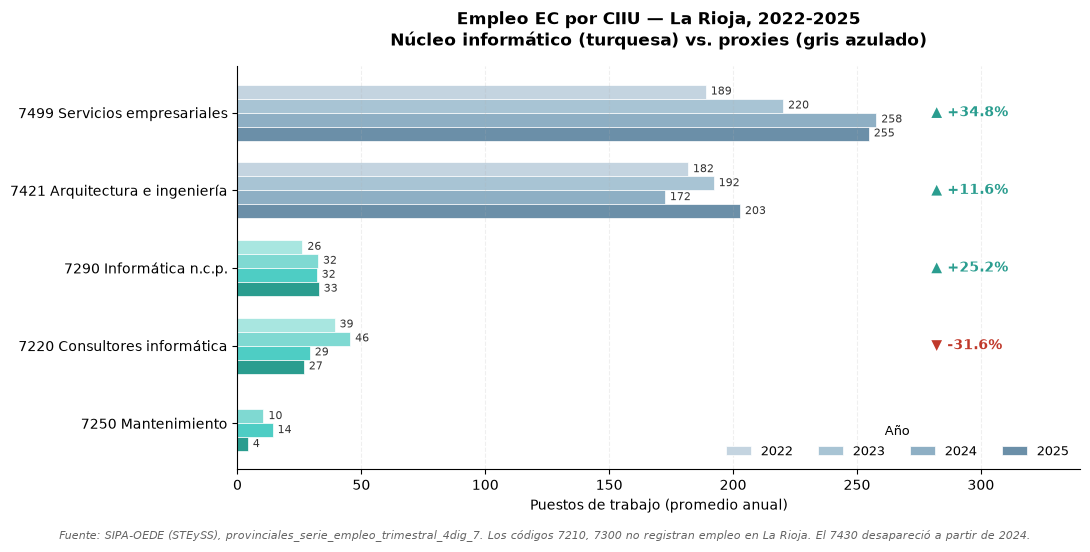

💾 C:\Users\HP\Documents\Economy\economia_c\informe\figuras\empleo_ec_2022_2025_por_ciiu.png


In [4]:
# ============================================================
# Gráfico: Empleo EC por CIIU — Serie 2022-2025
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
salida = RAIZ / 'informe' / 'figuras'
salida.mkdir(parents=True, exist_ok=True)

# Datos
datos = [
    ('7499', 'Servicios empresariales',    189.0, 220.2, 257.8, 254.8, 'Proxy'),
    ('7421', 'Arquitectura e ingeniería',  181.8, 192.2, 172.5, 202.8, 'Proxy'),
    ('7290', 'Informática n.c.p.',          26.2,  32.5,  32.0,  32.8, 'Núcleo'),
    ('7220', 'Consultores informática',     39.2,  45.5,  29.2,  26.8, 'Núcleo'),
    ('7250', 'Mantenimiento',                0.0,  10.5,  14.2,   4.2, 'Núcleo'),
]
df = pd.DataFrame(datos, columns=['CIIU', 'Rama', '2022', '2023', '2024', '2025', 'Tipo'])

# Colores por año (turquesa para núcleo, gris azulado para proxy)
COLORES_NUCLEO = ['#A8E6E0', '#7FD9D2', '#4ECDC4', '#2A9D8F']
COLORES_PROXY  = ['#C4D4E0', '#A8C4D4', '#8EAFC4', '#6B8FA8']

fig, ax = plt.subplots(figsize=(11, 5.5))

y = np.arange(len(df))
ancho = 0.18
anios = ['2022', '2023', '2024', '2025']

for i, anio in enumerate(anios):
    offset = (i - 1.5) * ancho
    colores = [COLORES_NUCLEO[i] if t == 'Núcleo' else COLORES_PROXY[i] for t in df['Tipo']]
    bars = ax.barh(y + offset, df[anio], ancho,
                   color=colores, edgecolor='white', linewidth=0.5,
                   label=anio)
    # Etiquetas de valor para los que tienen dato >0
    for b, v in zip(bars, df[anio]):
        if v > 2:
            ax.text(v + 2, b.get_y() + b.get_height()/2,
                    f'{v:.0f}', va='center', fontsize=8, color='#333')

# Etiquetas de variación a la derecha
for i, row in df.iterrows():
    var_pct = (row['2025'] / row['2022'] - 1) * 100 if row['2022'] > 0 else None
    if var_pct is not None:
        signo = '+' if var_pct >= 0 else ''
        color = '#2A9D8F' if var_pct >= 0 else '#C0392B'
        flecha = '▲' if var_pct >= 0 else '▼'
        ax.text(280, i,
                f'{flecha} {signo}{var_pct:.1f}%',
                va='center', fontsize=10, fontweight='bold', color=color)

ax.set_yticks(y)
ax.set_yticklabels([f'{r["CIIU"]} {r["Rama"]}' for _, r in df.iterrows()], fontsize=10)
ax.invert_yaxis()
ax.set_xlabel('Puestos de trabajo (promedio anual)', fontsize=10)
ax.set_title('Empleo EC por CIIU — La Rioja, 2022-2025\n'
             'Núcleo informático (turquesa) vs. proxies (gris azulado)',
             fontsize=12, fontweight='bold', pad=15)
ax.set_xlim(0, 340)
ax.grid(axis='x', alpha=0.2, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Leyenda de años
ax.legend(loc='lower right', frameon=False, fontsize=9, ncol=4, title='Año',
          title_fontsize=9)

# Nota al pie
fig.text(0.5, 0.01,
         'Fuente: SIPA-OEDE (STEySS), provinciales_serie_empleo_trimestral_4dig_7. '
         'Los códigos 7210, 7300 no registran empleo en La Rioja. '
         'El 7430 desapareció a partir de 2024.',
         ha='center', fontsize=8, color='#666', style='italic')

plt.tight_layout(rect=[0, 0.03, 1, 1])
ruta_fig = salida / 'empleo_ec_2022_2025_por_ciiu.png'
plt.savefig(ruta_fig, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f'💾 {ruta_fig}')

In [1]:
# ============================================================
# Empleo EC 2025 — Detalle trimestral por los 8 códigos CIIU
# Fuente: provinciales_serie_empleo_trimestral_4dig_7.xlsx
# ============================================================
import numpy as np
import pandas as pd
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
ruta = RAIZ / 'data' / 'raw' / 'provinciales_serie_empleo_trimestral_4dig_7.xlsx'

# --- Leer hoja La Rioja ---
df = pd.read_excel(ruta, sheet_name='La Rioja', header=6)
df = df.rename(columns={df.columns[0]: 'ciiu_raw', df.columns[1]: 'descripcion'})
df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()
df = df[df['ciiu_str'].str.fullmatch(r'\d{4}')].copy()
df['ciiu'] = df['ciiu_str'].astype(int)

# --- Los 8 códigos EC ---
CIIU_EC = {
    7210: 'Consultores en equipo de informática',
    7220: 'Consultores en informática',
    7250: 'Mantenimiento y reparación informática',
    7290: 'Informática n.c.p.',
    7300: 'Investigación y desarrollo',
    7421: 'Arquitectura e ingeniería',
    7430: 'Servicios de publicidad',
    7499: 'Servicios empresariales n.c.p.',
}

# --- Trimestres 2025 ---
cols_2025 = [c for c in df.columns if isinstance(c, str) and 'Trim 2025' in c]
print(f'📅 Trimestres 2025: {cols_2025}')

for c in cols_2025:
    df[c] = pd.to_numeric(df[c], errors='coerce')

# --- Armar tabla ---
filas = []
for ciiu, nombre in CIIU_EC.items():
    fila = df[df['ciiu'] == ciiu]
    if fila.empty:
        vals = [None, None, None, None]
    else:
        vals = [fila[c].iloc[0] for c in cols_2025]
    validos = [v for v in vals if pd.notna(v)]
    prom = round(np.mean(validos), 1) if validos else 0
    filas.append({
        'CIIU': ciiu,
        'Rama': nombre,
        '1° T 2025': vals[0],
        '2° T 2025': vals[1],
        '3° T 2025': vals[2],
        '4° T 2025': vals[3],
        'Promedio 2025': prom,
    })

tabla = pd.DataFrame(filas)

# --- Mostrar ---
print('\n' + '=' * 110)
print('📊 EMPLEO EC 2025 — DETALLE TRIMESTRAL POR CÓDIGO CIIU')
print('=' * 110)
print(f'\n{"CIIU":<6} {"Rama":<42} {"1°T":>7} {"2°T":>7} {"3°T":>7} {"4°T":>7} {"Prom":>9}')
print('-' * 110)

for _, r in tabla.iterrows():
    def fmt(v):
        return f'{v:.0f}' if pd.notna(v) else 's/d'
    print(f'{r["CIIU"]:<6} {r["Rama"]:<42} '
          f'{fmt(r["1° T 2025"]):>7} {fmt(r["2° T 2025"]):>7} '
          f'{fmt(r["3° T 2025"]):>7} {fmt(r["4° T 2025"]):>7} '
          f'{r["Promedio 2025"]:>9.1f}')

# --- Totales por trimestre ---
print('-' * 110)

tot = {trim: 0 for trim in ['1° T 2025', '2° T 2025', '3° T 2025', '4° T 2025']}
for _, r in tabla.iterrows():
    for trim in tot:
        v = r[trim]
        if pd.notna(v):
            tot[trim] += v

total_prom = tabla['Promedio 2025'].sum()

print(f'{"":<6} {"TOTAL EC (8 CIIU)":<42} '
      f'{tot["1° T 2025"]:>7.0f} {tot["2° T 2025"]:>7.0f} '
      f'{tot["3° T 2025"]:>7.0f} {tot["4° T 2025"]:>7.0f} '
      f'{total_prom:>9.1f}')

# --- Desglose por tipo ---
print('\n' + '=' * 110)
print('📊 DESGLOSE POR TIPO — 2025')
print('=' * 110)

NUCLEO = {7220, 7250, 7290}
AMPLIO = {7210, 7300, 7430}
PROXY = {7421, 7499}

nucleo_total = tabla[tabla['CIIU'].isin(NUCLEO)]['Promedio 2025'].sum()
amplio_total = tabla[tabla['CIIU'].isin(AMPLIO)]['Promedio 2025'].sum()
proxy_total = tabla[tabla['CIIU'].isin(PROXY)]['Promedio 2025'].sum()

print(f'\n   Núcleo informático (7220+7250+7290):   {nucleo_total:>8.1f}  ({nucleo_total/total_prom*100:.1f}%)')
print(f'   Núcleo amplio (7210+7300+7430):        {amplio_total:>8.1f}  ({amplio_total/total_prom*100:.1f}%)')
print(f'   Proxies (7421+7499):                   {proxy_total:>8.1f}  ({proxy_total/total_prom*100:.1f}%)')
print(f'   {"─" * 50}')
print(f'   TOTAL EC 2025:                         {total_prom:>8.1f}')

# --- Datos que aportan ---
print('\n📌 Códigos con datos:')
con_datos = tabla[tabla['Promedio 2025'] > 0]
print(f'   {len(con_datos)} de 8 códigos')

for _, r in con_datos.iterrows():
    print(f'   {r["CIIU"]} — {r["Rama"]:<42} {r["Promedio 2025"]:>8.1f}')

print('\n📌 Códigos SIN datos:')
sin_datos = tabla[tabla['Promedio 2025'] == 0]
for _, r in sin_datos.iterrows():
    print(f'   {r["CIIU"]} — {r["Rama"]}')

# --- Exportar ---
out = RAIZ / 'data' / 'processed' / 'empleo_ec_2025_trimestral.csv'
tabla.to_csv(out, index=False, encoding='utf-8-sig')
print(f'\n💾 {out}')

📅 Trimestres 2025: ['1° Trim 2025', '2° Trim 2025', '3° Trim 2025', '4° Trim 2025']

📊 EMPLEO EC 2025 — DETALLE TRIMESTRAL POR CÓDIGO CIIU

CIIU   Rama                                           1°T     2°T     3°T     4°T      Prom
--------------------------------------------------------------------------------------------------------------
7210   Consultores en equipo de informática           s/d     s/d     s/d     s/d       0.0
7220   Consultores en informática                      27      27      28      25      26.8
7250   Mantenimiento y reparación informática           6       6       4       1       4.2
7290   Informática n.c.p.                              29      32      36      34      32.8
7300   Investigación y desarrollo                     s/d     s/d     s/d     s/d       0.0
7421   Arquitectura e ingeniería                      172     225     217     197     202.8
7430   Servicios de publicidad                        s/d     s/d     s/d     s/d       0.0
7499   Servic

C:\Users\HP\AppData\Local\Temp\ipykernel_15228\4223883520.py:15: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['ciiu_str'] = df['ciiu_raw'].astype(str).str.strip()


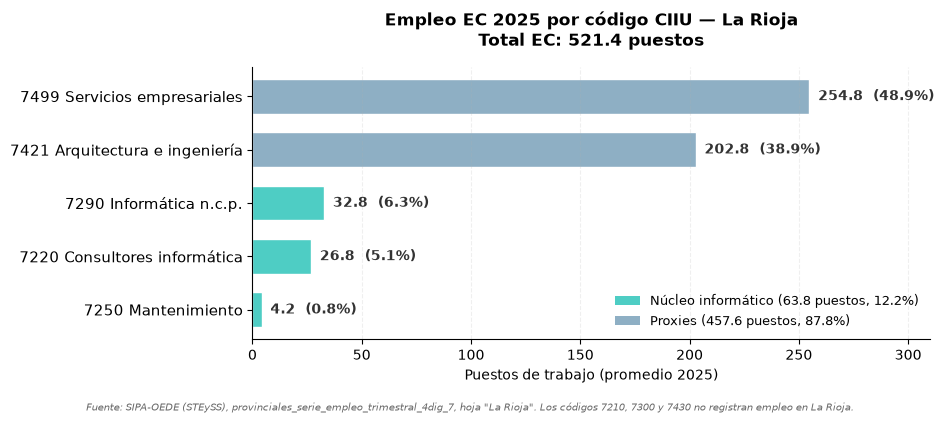

💾 F41_empleo_ec_2025_por_ciiu.png
   Ruta: C:\Users\HP\Documents\Economy\economia_c\informe\figuras\F41_empleo_ec_2025_por_ciiu.png


In [1]:
# ============================================================
# Figura para el informe: Empleo EC 2025 por código CIIU
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
salida = RAIZ / 'informe' / 'figuras'
salida.mkdir(parents=True, exist_ok=True)

# --- Datos ---
datos = [
    ('7499 Servicios empresariales', 254.8, 'Proxy'),
    ('7421 Arquitectura e ingeniería', 202.8, 'Proxy'),
    ('7290 Informática n.c.p.',       32.8,  'Núcleo informático'),
    ('7220 Consultores informática',  26.8,  'Núcleo informático'),
    ('7250 Mantenimiento',             4.2,  'Núcleo informático'),
]
df = pd.DataFrame(datos, columns=['Rama', 'Empleo', 'Tipo'])
total = df['Empleo'].sum()

# --- Colores coherentes con el dashboard ---
COLOR_NUCLEO = '#4ECDC4'   # turquesa
COLOR_PROXY  = '#8EAFC4'   # gris azulado

colores = {
    'Núcleo informático': COLOR_NUCLEO,
    'Proxy': COLOR_PROXY,
}

# --- Figura ---
fig, ax = plt.subplots(figsize=(9.5, 4.2))

y = np.arange(len(df))
bars = ax.barh(y, df['Empleo'],
               color=[colores[t] for t in df['Tipo']],
               height=0.65, edgecolor='white', linewidth=1)

# Etiquetas de valor
for b, v in zip(bars, df['Empleo']):
    pct = v / total * 100
    ax.text(v + 4, b.get_y() + b.get_height()/2,
            f'{v:.1f}  ({pct:.1f}%)',
            va='center', fontsize=10, fontweight='bold', color='#333')

# --- Configuración ---
ax.set_yticks(y)
ax.set_yticklabels(df['Rama'], fontsize=11)
ax.invert_yaxis()
ax.set_xlabel('Puestos de trabajo (promedio 2025)', fontsize=10)
ax.set_title(
    f'Empleo EC 2025 por código CIIU — La Rioja\n'
    f'Total EC: {total:.1f} puestos',
    fontsize=12, fontweight='bold', pad=15
)
ax.set_xlim(0, 310)
ax.grid(axis='x', alpha=0.2, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- Leyenda ---
nucleo_total = df[df['Tipo'] == 'Núcleo informático']['Empleo'].sum()
proxy_total = df[df['Tipo'] == 'Proxy']['Empleo'].sum()

leyenda = [
    Patch(facecolor=COLOR_NUCLEO,
          label=f'Núcleo informático ({nucleo_total:.1f} puestos, {nucleo_total/total*100:.1f}%)'),
    Patch(facecolor=COLOR_PROXY,
          label=f'Proxies ({proxy_total:.1f} puestos, {proxy_total/total*100:.1f}%)'),
]
ax.legend(handles=leyenda, loc='lower right', frameon=False, fontsize=9)

# --- Nota al pie ---
fig.text(0.5, 0.01,
         'Fuente: SIPA-OEDE (STEySS), provinciales_serie_empleo_trimestral_4dig_7, hoja "La Rioja". '
         'Los códigos 7210, 7300 y 7430 no registran empleo en La Rioja.',
         ha='center', fontsize=7.5, color='#666', style='italic')

plt.tight_layout(rect=[0, 0.04, 1, 1])

# --- Guardar ---
ruta_fig = salida / 'F41_empleo_ec_2025_por_ciiu.png'
plt.savefig(ruta_fig, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f'💾 {ruta_fig.name}')
print(f'   Ruta: {ruta_fig}')

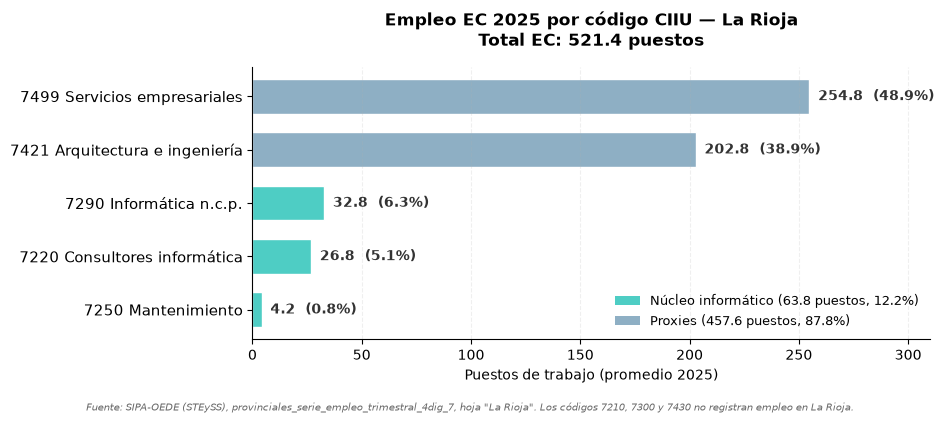

💾 F41_empleo_ec_2025_por_ciiu.png
   Ruta: C:\Users\HP\Documents\Economy\economia_c\informe\figuras\F41_empleo_ec_2025_por_ciiu.png


In [2]:
# ============================================================
# Figura para el informe: Empleo EC 2025 por código CIIU
# Leyenda: "Núcleo informático" (no "Núcleo software")
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path

RAIZ = Path(r'C:\Users\HP\Documents\Economy\economia_c')
salida = RAIZ / 'informe' / 'figuras'
salida.mkdir(parents=True, exist_ok=True)

# --- Datos ---
datos = [
    ('7499 Servicios empresariales', 254.8, 'Proxy'),
    ('7421 Arquitectura e ingeniería', 202.8, 'Proxy'),
    ('7290 Informática n.c.p.',       32.8,  'Núcleo informático'),
    ('7220 Consultores informática',  26.8,  'Núcleo informático'),
    ('7250 Mantenimiento',             4.2,  'Núcleo informático'),
]
df = pd.DataFrame(datos, columns=['Rama', 'Empleo', 'Tipo'])
total = df['Empleo'].sum()

# --- Colores coherentes con el dashboard ---
COLOR_NUCLEO = '#4ECDC4'
COLOR_PROXY  = '#8EAFC4'

colores = {
    'Núcleo informático': COLOR_NUCLEO,
    'Proxy': COLOR_PROXY,
}

# --- Figura ---
fig, ax = plt.subplots(figsize=(9.5, 4.2))

y = np.arange(len(df))
bars = ax.barh(y, df['Empleo'],
               color=[colores[t] for t in df['Tipo']],
               height=0.65, edgecolor='white', linewidth=1)

for b, v in zip(bars, df['Empleo']):
    pct = v / total * 100
    ax.text(v + 4, b.get_y() + b.get_height()/2,
            f'{v:.1f}  ({pct:.1f}%)',
            va='center', fontsize=10, fontweight='bold', color='#333')

ax.set_yticks(y)
ax.set_yticklabels(df['Rama'], fontsize=11)
ax.invert_yaxis()
ax.set_xlabel('Puestos de trabajo (promedio 2025)', fontsize=10)
ax.set_title(
    f'Empleo EC 2025 por código CIIU — La Rioja\n'
    f'Total EC: {total:.1f} puestos',
    fontsize=12, fontweight='bold', pad=15
)
ax.set_xlim(0, 310)
ax.grid(axis='x', alpha=0.2, linestyle='--')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# --- Leyenda (con "Núcleo informático") ---
nucleo_total = df[df['Tipo'] == 'Núcleo informático']['Empleo'].sum()
proxy_total = df[df['Tipo'] == 'Proxy']['Empleo'].sum()

leyenda = [
    Patch(facecolor=COLOR_NUCLEO,
          label=f'Núcleo informático ({nucleo_total:.1f} puestos, {nucleo_total/total*100:.1f}%)'),
    Patch(facecolor=COLOR_PROXY,
          label=f'Proxies ({proxy_total:.1f} puestos, {proxy_total/total*100:.1f}%)'),
]
ax.legend(handles=leyenda, loc='lower right', frameon=False, fontsize=9)

fig.text(0.5, 0.01,
         'Fuente: SIPA-OEDE (STEySS), provinciales_serie_empleo_trimestral_4dig_7, hoja "La Rioja". '
         'Los códigos 7210, 7300 y 7430 no registran empleo en La Rioja.',
         ha='center', fontsize=7.5, color='#666', style='italic')

plt.tight_layout(rect=[0, 0.04, 1, 1])

ruta_fig = salida / 'F41_empleo_ec_2025_por_ciiu.png'
plt.savefig(ruta_fig, dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print(f'💾 {ruta_fig.name}')
print(f'   Ruta: {ruta_fig}')